# 항만구분 OLS: 전처리부터 모형 비교와 특보 KPI까지

## 1. 분석 목적과 후보 모형
체류시간과 선박·작업·기상의 관계를 설명하고, 다른 조건을 고정한 특보 시나리오 차이를 계산한다.
원본 파일을 바꾸지 않고 모든 후보에 동일한 학습·평가 행을 사용한다.

P는 신항더미, G는 총톤수, Q는 총작업량, A는 특보유무, W는 기상 6개이다.
`*`는 주효과와 상호작용을 함께 포함한다.

| 이름 | 구성 |
|---|---|
| M1 | P |
| M2 | P*(G+Q) |
| M3 | P*(G+Q+A) |
| M4 | P*(G+Q+A+W) |
| M4_time | M4 + 월·요일·연도추세 |
| EXT | P*((G+Q)*(A+W)) |
| EXT_time | EXT + 월·요일·연도추세 |

시간 통제는 모든 항만에 공통이다. 연도 더미가 아니라 `접안연도-2021`을 사용한다.
확장 모형에는 총톤수·작업량×특보·각 기상과 해당 관계의 항만별 차이가 포함된다.
기존의 특보만 확장한 K 후보보다 넓은 구성이다.

**해석 범위:** 체류기간 전체의 기상 집계는 출항 후 알 수 있다. 따라서 2024년 평가는
사후 관측된 조건에서의 시간 외 검증이며, 입항 시점의 운영 예측이나 기상의 인과효과 검증은 아니다.
2024년을 이미 반복해서 확인했으므로 독립적인 최종 test라는 표현 대신 탐색적 시간 검증으로 제시한다.

In [19]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.sandwich_covariance import cov_cluster_2groups
from statsmodels.graphics.tsaplots import plot_acf
from IPython.display import display

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

PROJECT = Path(r'C:\WORK\stay_multiregression')
DATA_PATH = PROJECT / 'data' / '체류시간_찐최종.csv'
OUTPUT = PROJECT / 'outputs' / 'KPI1_항만_통합분석'
OUTPUT.mkdir(parents=True, exist_ok=True)

# 기존 32,014개 행과 비교하려면 True. 분석 관련 열만 기준으로 하려면 False.
MATCH_OLD_SAMPLE = True
DETAIL_MODELS = ['M4', 'M4_time', 'EXT_time']

## 2. 자료 불러오기와 전처리
`raw`는 보관하고 복사본 `work`를 정리한다. 쉼표 문자열은 숫자로 바꾸며,
변환 때문에 생긴 결측도 확인한다. 무한값은 유효한 관측값으로 쓰지 않는다.

기존 분석과 표본을 맞추기 위해 기본값은 **원래 모든 열의 결측행 제외**이다.
이 기준은 분석에 쓰지 않는 선사 등의 결측까지 제외한다. `MATCH_OLD_SAMPLE=False`이면
후보 기상 9개와 분석·진단에 필요한 열을 기준으로 제외한다. 어느 기준이든 모든 후보에 같은 행을 쓴다.
실제 극단값은 임의 삭제하지 않는다. 음수 작업량·풍속 등은 오류를 알리므로 원자료를 확인한다.

In [20]:
weather9 = [
    '체류시간_풍속_중앙값_mps',
    '체류시간_최대순간풍속_최댓값_mps',
    '체류시간_최대순간풍속_중앙값_mps',
    '체류시간_유의파고_중앙값_m',
    '체류시간_유의파고_최댓값_m',
    '체류시간_순간최대파고_최댓값_m',
    '체류시간_순간최대파고_중앙값_m',
    '체류시간_시정_최솟값_10m',
    '체류시간_시정_중앙값_10m',
]
# 팀원과 통일한 6개. 이번 노트북에서 VIF로 자동 변경하지 않는다.
weather6 = [weather9[i] for i in [0, 1, 3, 5, 7, 8]]
numeric_cols = ['체류시간', '총톤수', '총작업량',
                '체류시간_특보노출시간(h)'] + weather9
required = numeric_cols + ['항만구분', '접안일시', '출항일시', '선박명', '터미널']

try:
    raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig', low_memory=False)
except UnicodeDecodeError:
    raw = pd.read_csv(DATA_PATH, encoding='cp949', low_memory=False)

display(raw.isna().sum().rename('원자료 결측 수').to_frame())
work = raw.copy()
conversion = []
for col in numeric_cols:
    before = work[col].notna()
    work[col] = pd.to_numeric(
        work[col].astype('string').str.replace(',', '', regex=False),
        errors='coerce').astype(float)
    conversion.append([col, int((before & work[col].isna()).sum())])
work[numeric_cols] = work[numeric_cols].replace([np.inf, -np.inf], np.nan)
for col in ['접안일시', '출항일시']:
    work[col] = pd.to_datetime(work[col], errors='coerce')
work['항만구분'] = work['항만구분'].astype('string').str.strip()
work['신항더미'] = work['항만구분'].map({'북항': 0, '신항': 1})

keep = work[required + ['신항더미']].notna().all(axis=1)
if MATCH_OLD_SAMPLE:
    keep &= raw.notna().all(axis=1)
df = work.loc[keep].copy()
df['신항더미'] = df['신항더미'].astype(float)
if (df[numeric_cols] < 0).any().any():
    raise ValueError('음수인 분석값이 있습니다. 원자료를 확인하세요.')
if (df['체류시간'] <= 0).any() or (df['출항일시'] < df['접안일시']).any():
    raise ValueError('체류시간 또는 접안·출항 순서를 확인하세요.')
df['특보유무'] = (df['체류시간_특보노출시간(h)'] > 0).astype(float)
df['월'] = df['접안일시'].dt.month
df['요일'] = df['접안일시'].dt.day_of_week  # 월요일=0
df['연도추세'] = df['접안일시'].dt.year - 2021
df['행ID'] = df.index

display(pd.DataFrame(conversion, columns=['변수', '숫자 변환 중 생긴 결측 수']))
display(pd.DataFrame({'원자료': [len(raw)], '분석자료': [len(df)],
                      '제외': [len(raw)-len(df)]}))
display(df.groupby('항만구분')['체류시간'].agg(['count', 'mean', 'std']))

,원자료 결측 수
선박명,0
총톤수,0
항만구분,0
터미널,0
선사,1
접안일시,0
출항일시,0
체류시간,0
순수물동량,0
Shift수량,0


,변수,숫자 변환 중 생긴 결측 수
0,체류시간,0
1,총톤수,0
2,총작업량,0
3,체류시간_특보노출시간(h),0
4,체류시간_풍속_중앙값_mps,0
5,체류시간_최대순간풍속_최댓값_mps,0
6,체류시간_최대순간풍속_중앙값_mps,0
7,체류시간_유의파고_중앙값_m,0
8,체류시간_유의파고_최댓값_m,0
9,체류시간_순간최대파고_최댓값_m,0


,원자료,분석자료,제외
0,33994,32014,1980


,count,mean,std
항만구분,,,
북항,16404,17.723461,7.666841
신항,15610,22.452156,10.512011


## 3. 학습·검증자료 분리
2021~2023년에 접안하고 **2024년 시작 전에 출항한 기록**을 학습에 쓴다.
2024년 접안 기록 중 2025년 시작 전에 출항한 기록을 검증에 쓴다.
연말 경계를 넘는 체류는 별도 표로 보관하고 제외한다. 기존 분리 결과와 비교할 수 있다.

이후 산점도·VIF·중심화 기준·영향력 진단은 학습자료로 계산한다.
연도추세는 미래 연도로 연장할 수 있지만, 그 추세가 계속된다는 가정이 추가된다.

In [21]:
train_mask = (df['접안일시'] >= '2021-01-01') & (df['출항일시'] < '2024-01-01')
test_mask = (df['접안일시'] >= '2024-01-01') & (df['접안일시'] < '2025-01-01') & (df['출항일시'] < '2025-01-01')
train = df.loc[train_mask].copy()
test = df.loc[test_mask].copy()
boundary = df.loc[~(train_mask | test_mask)].copy()
assert len(train) > 0 and len(test) > 0
assert set(train['행ID']).isdisjoint(test['행ID'])
display(pd.DataFrame({'자료': ['학습 2021~2023', '검증 2024', '경계 등 제외'],
                      '행 수': [len(train), len(test), len(boundary)]}))
display(boundary[['행ID', '접안일시', '출항일시']].head())
train[['행ID']].to_csv(OUTPUT / '학습_행ID.csv', index=False, encoding='utf-8-sig')
test[['행ID']].to_csv(OUTPUT / '검증_행ID.csv', index=False, encoding='utf-8-sig')

,자료,행 수
0,학습 2021~2023,23557
1,검증 2024,8442
2,경계 등 제외,15


,행ID,접안일시,출항일시
2338,2338,2023-12-31 00:16:00,2024-01-01 11:54:00
8241,8241,2023-12-31 15:00:00,2024-01-01 03:00:00
8242,8242,2023-12-31 12:40:00,2024-01-01 19:00:00
8243,8243,2023-12-31 23:20:00,2024-01-01 17:00:00
18235,18235,2023-12-31 08:30:00,2024-01-01 05:00:00


## 4. 학습자료에서 변수 관계 검토
### 4-1. 원자료 산점도
항만별 산점도와 최대 20개 분위 구간의 평균을 그린다.
이 선은 LOWESS가 아닌 구간 평균이며, 관측이 적은 구간의 선 모양은 신중히 해석한다.
다른 변수를 고려하기 전의 관계이므로 평평하다는 이유로 변수를 바로 제거하지 않는다.

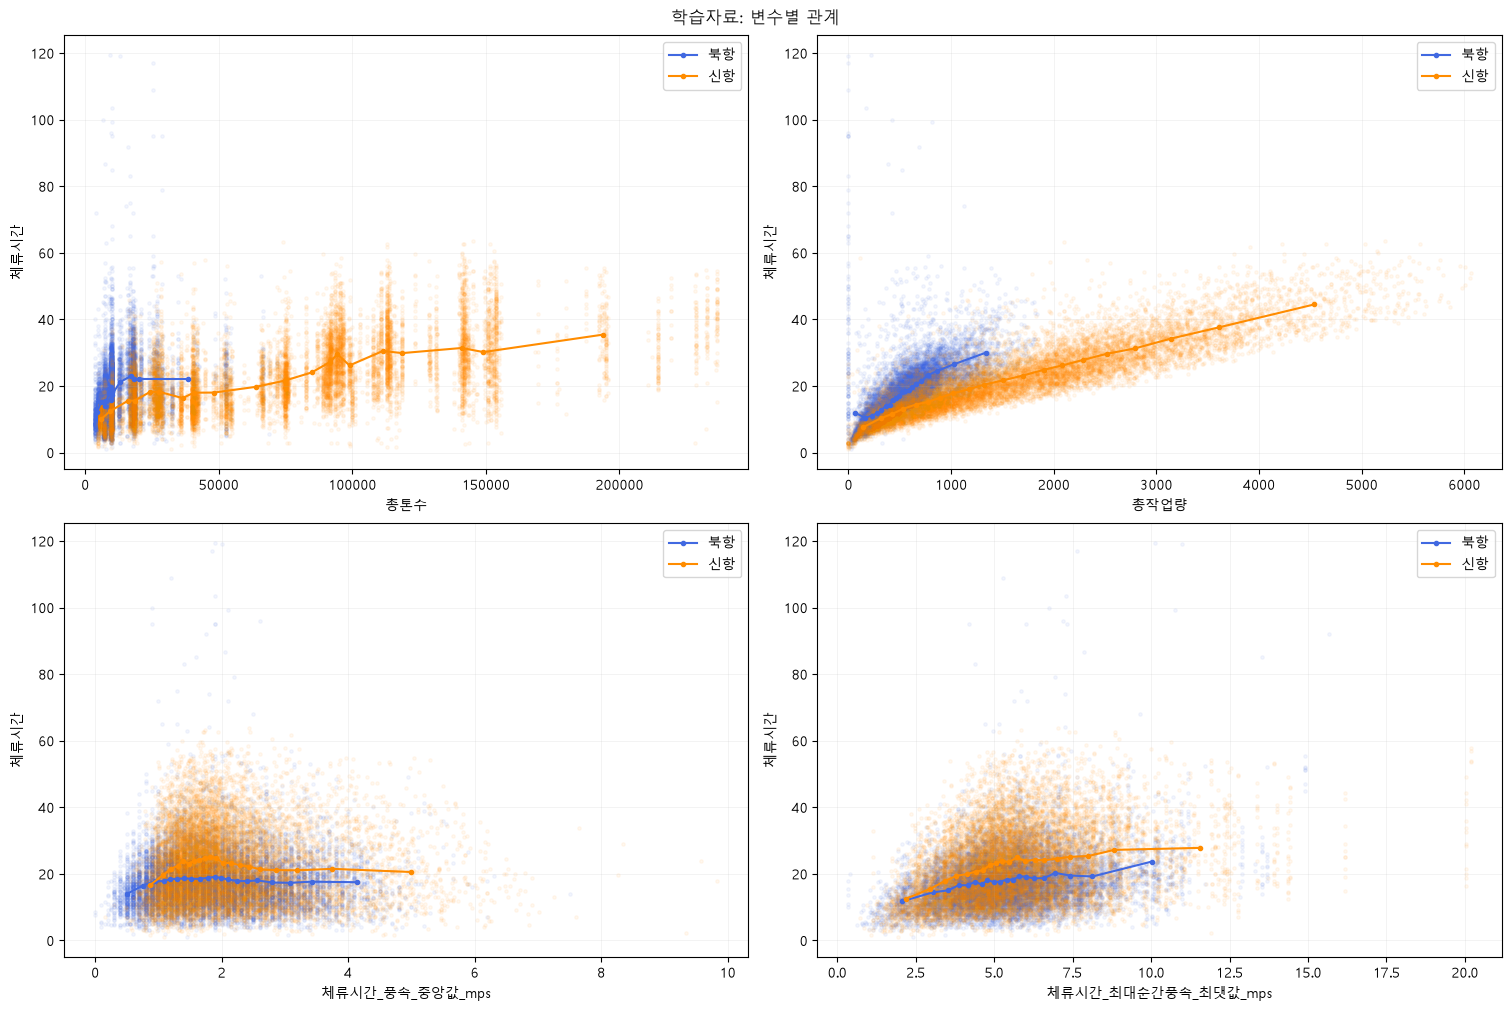

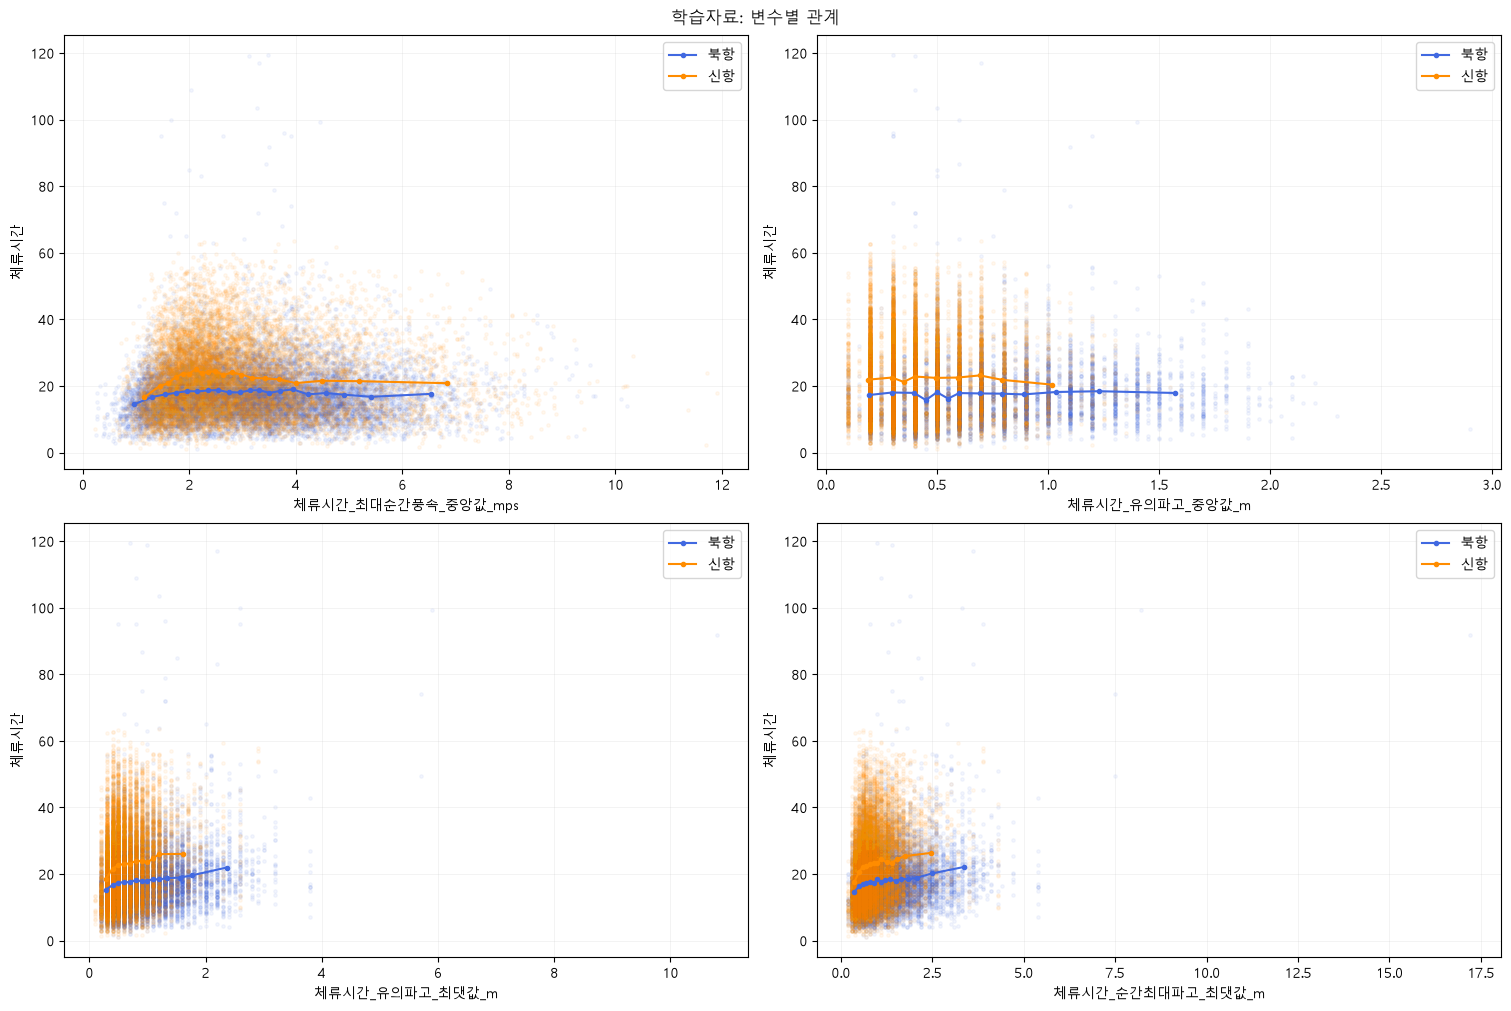

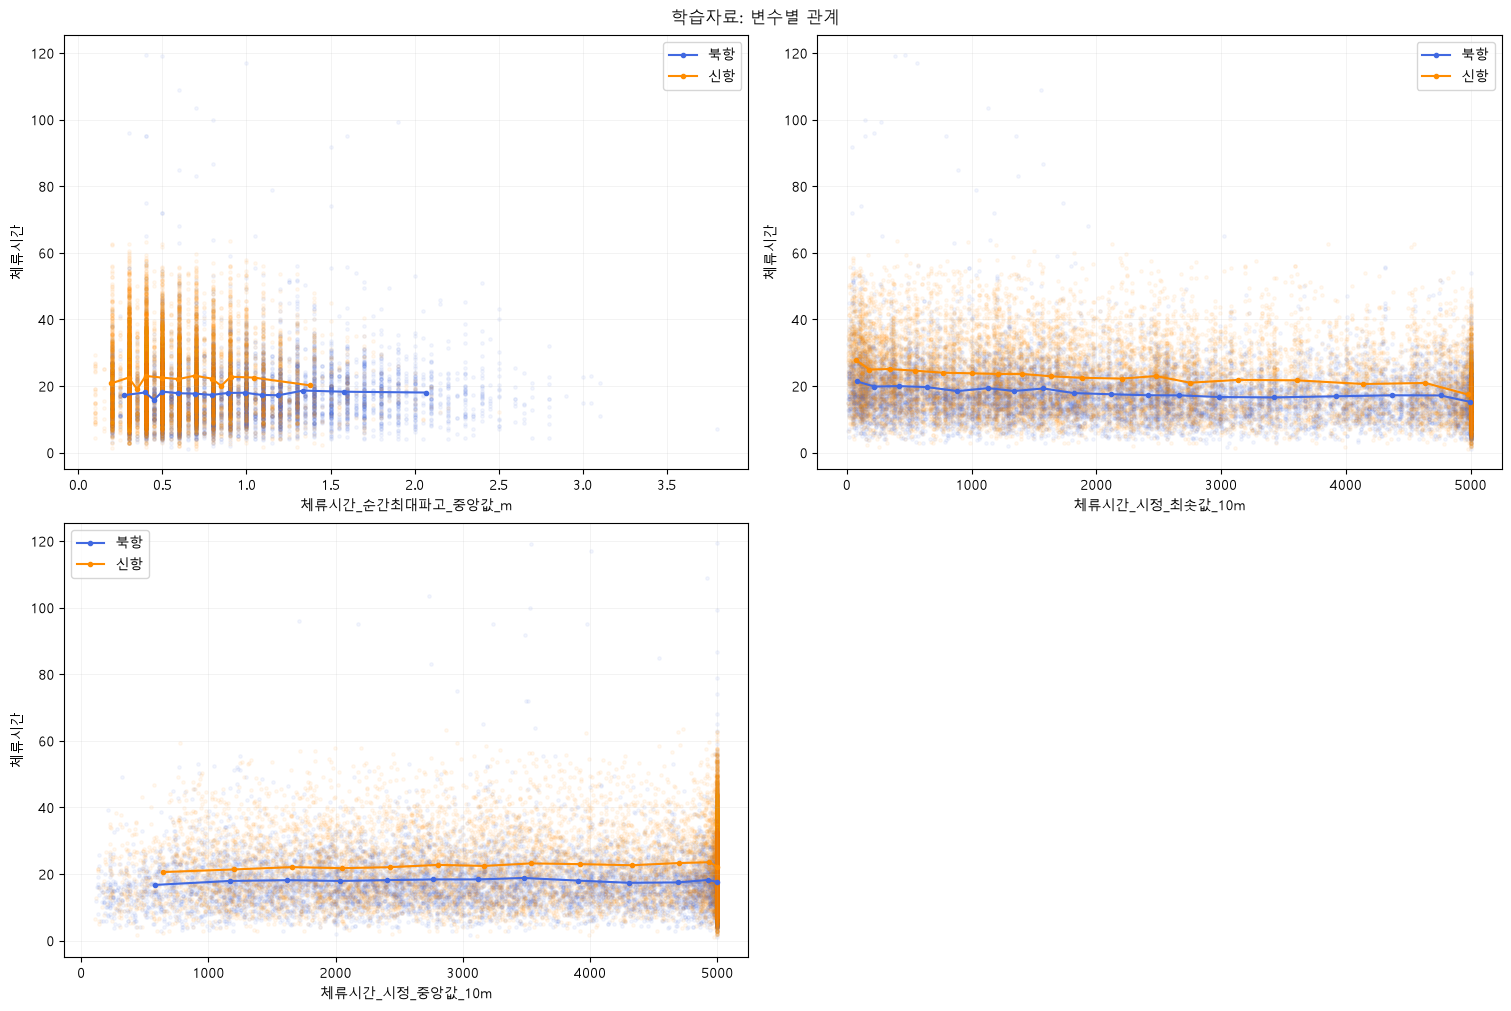

In [22]:
colors = {'북항': 'royalblue', '신항': 'darkorange'}

def scatter_trend(ax, data, x_col, y_col):
    for port, color in colors.items():
        part = data.loc[data['항만구분'].eq(port), [x_col, y_col]].dropna()
        ax.scatter(part[x_col], part[y_col], s=6, alpha=0.06, color=color, rasterized=True)
        if part[x_col].nunique() > 1:
            bins = pd.qcut(part[x_col], q=20, duplicates='drop')
            trend = part.groupby(bins, observed=True).agg(
                x=(x_col, 'mean'), y=(y_col, 'mean'), n=(y_col, 'size'))
            ax.plot(trend['x'], trend['y'], marker='o', markersize=3,
                    color=color, label=port)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.grid(alpha=0.2)
    ax.legend()

def plot_grid(data, columns, y_col, title, zero=False):
    for start in range(0, len(columns), 4):
        fig, axes = plt.subplots(2, 2, figsize=(15, 10), layout='constrained')
        batch = columns[start:start+4]
        for ax, col in zip(axes.flat, batch):
            scatter_trend(ax, data, col, y_col)
            if zero:
                ax.axhline(0, color='red', linestyle='--')
        for ax in list(axes.flat)[len(batch):]:
            ax.set_visible(False)
        fig.suptitle(title)
        plt.show()

plot_grid(train, ['총톤수', '총작업량'] + weather9, '체류시간', '학습자료: 변수별 관계')

### 4-2. 항만별 VIF와 변수 구성의 근거
상수항을 포함해 VIF를 계산하고 상수항은 표에서 뺀다. 항만 내부에서는 항만더미를 넣지 않는다.
우선 원래 기상 9개와 기존 선택 6개를 각각 비교한다.

**이번 주 분석의 6개는 기존 분석 및 팀원과의 비교를 위해 고정한 구성이다.**
이전 분석에서 2024년도 확인했으므로 완전히 새로운 학습 전용 선정이라고 주장하지 않는다.
아래 제거 순서 시뮬레이션은 학습자료에서 기상변수만 VIF>10이면 하나씩 제외하는 참고 결과다.
항만별 결과가 다를 수 있으며 실제 후보 변수 목록은 자동으로 바꾸지 않는다.

In [23]:
def vif_table(data):
    varying = data.loc[:, data.nunique() > 1].astype(float)
    const = sm.add_constant(varying, has_constant='add').to_numpy()
    return pd.DataFrame({'변수': varying.columns, 'VIF': [
        variance_inflation_factor(const, i+1) for i in range(varying.shape[1])
    ]}).sort_values('VIF', ascending=False).reset_index(drop=True)

def port_vif(data, columns):
    tables = []
    for port in colors:
        table = vif_table(data.loc[data['항만구분'].eq(port), columns])
        tables.append(table.set_index('변수').rename(columns={'VIF': port}))
    return pd.concat(tables, axis=1)

for label, weather in [('기상 9개', weather9), ('고정 기상 6개', weather6)]:
    print(label)
    display(port_vif(train, ['총톤수', '총작업량', '특보유무'] + weather).round(3))

selection_records = []
for port in colors:
    columns = ['총톤수', '총작업량', '특보유무'] + weather9.copy()
    part = train.loc[train['항만구분'].eq(port)]
    while True:
        table = vif_table(part[columns])
        eligible = table.loc[table['변수'].isin(weather9) & table['VIF'].gt(10)]
        if eligible.empty:
            break
        row = eligible.iloc[0]
        selection_records.append([port, row['변수'], row['VIF']])
        columns.remove(row['변수'])
selection_history = pd.DataFrame(selection_records, columns=['항만', '참고용 제거 순서의 변수', '제거 당시 VIF'])
display(selection_history)
print('실제 모형에 사용할 고정 기상변수:', weather6)

기상 9개


,북항,신항
변수,,
체류시간_순간최대파고_중앙값_m,56.673,21.475
체류시간_유의파고_중앙값_m,53.955,19.856
체류시간_유의파고_최댓값_m,29.207,11.805
체류시간_순간최대파고_최댓값_m,28.549,9.350
체류시간_최대순간풍속_중앙값_mps,7.501,24.932
체류시간_풍속_중앙값_mps,6.064,23.048
체류시간_최대순간풍속_최댓값_mps,2.948,2.466
체류시간_시정_최솟값_10m,2.365,2.255
체류시간_시정_중앙값_10m,2.304,2.139


고정 기상 6개


,북항,신항
변수,,
체류시간_순간최대파고_최댓값_m,4.075,2.775
체류시간_유의파고_중앙값_m,3.992,2.815
체류시간_최대순간풍속_최댓값_mps,2.545,2.374
체류시간_시정_최솟값_10m,2.351,2.201
체류시간_시정_중앙값_10m,2.282,2.114
체류시간_풍속_중앙값_mps,2.268,2.117
특보유무,1.633,1.568
총작업량,1.479,2.415
총톤수,1.313,2.122


,항만,참고용 제거 순서의 변수,제거 당시 VIF
0,북항,체류시간_순간최대파고_중앙값_m,56.672698
1,북항,체류시간_유의파고_최댓값_m,27.345582
2,신항,체류시간_최대순간풍속_중앙값_mps,24.932324
3,신항,체류시간_순간최대파고_중앙값_m,21.268319
4,신항,체류시간_유의파고_최댓값_m,11.581645


실제 모형에 사용할 고정 기상변수: ['체류시간_풍속_중앙값_mps', '체류시간_최대순간풍속_최댓값_mps', '체류시간_유의파고_중앙값_m', '체류시간_순간최대파고_최댓값_m', '체류시간_시정_최솟값_10m', '체류시간_시정_중앙값_10m']


## 5. 후보 모형 적합
반복 코드를 줄이기 위해 설계행렬을 한 함수로 만든다. 연속형 변수는 **학습 평균**을 빼고
학습 표준편차로 나눈다. 상호작용도 이 값을 사용한다. 중심화·단위 변경은 필요한 하위항을
모두 포함한 현재 모형에서 예측 가능한 함수의 범위를 바꾸지 않는다. 계수 단위는 달라진다.

특보는 0/1을 유지한다. 확장 모형은 모든 하위항을 유지해 계층성을 지킨다.
전 후보의 표본, 목적변수, 날씨 6개는 동일하다. AIC/BIC는 동일한 원단위 Y의 OLS끼리 비교한다.
학습 계수표는 HC3 표준오차로 표시한다. HC3는 이분산성 보정이며 시간·집단 의존성을
해결하지 않는다. 특보 KPI와 최종 계수는 뒤에서 이중 군집 공분산도 따로 검토한다.

In [24]:
continuous = ['총톤수', '총작업량'] + weather6
centers = train[continuous].mean()
scales = train[continuous].std()
if (scales <= 0).any():
    raise ValueError('값이 일정한 연속형 변수가 있습니다.')

specs = {
    'M1': {'stage': 1},
    'M2': {'stage': 2},
    'M3': {'stage': 3},
    'M4': {'stage': 4},
    'M4_time': {'stage': 4, 'time': True},
    'EXT': {'stage': 4, 'expanded': True},
    'EXT_time': {'stage': 4, 'expanded': True, 'time': True},
}

def make_design(frame, spec, alert=None):
    x = pd.DataFrame({'신항더미': frame['신항더미'].astype(float)}, index=frame.index)
    main = []
    if spec['stage'] >= 2:
        main += ['총톤수', '총작업량']
    if spec['stage'] >= 3:
        main += ['특보유무']
    if spec['stage'] >= 4:
        main += weather6
    for col in main:
        if col == '특보유무':
            x[col] = frame[col] if alert is None else float(alert)
        else:
            x[col] = (frame[col] - centers[col]) / scales[col]
        x[f'신항더미 × {col}'] = x['신항더미'] * x[col]
    if spec.get('expanded', False):
        for size in ['총톤수', '총작업량']:
            for other in ['특보유무'] + weather6:
                term = f'{size} × {other}'
                x[term] = x[size] * x[other]
                x[f'신항더미 × {term}'] = x['신항더미'] * x[term]
    if spec.get('time', False):
        # 범주를 고정해 학습·검증·시나리오의 열 순서를 일치시킨다.
        for col, categories in [('월', range(1, 13)), ('요일', range(7))]:
            cat = pd.Series(pd.Categorical(frame[col], categories=categories), index=frame.index)
            x = pd.concat([x, pd.get_dummies(cat, prefix=col, drop_first=True, dtype=float)], axis=1)
        x['연도추세'] = frame['연도추세']
    return sm.add_constant(x, has_constant='add').astype(float)

models, designs, predictions = {}, {}, {}
fit_rows = []
for name, spec in specs.items():
    x = make_design(train, spec)
    xt = make_design(test, spec)
    assert x.columns.equals(xt.columns)
    if np.linalg.matrix_rank(x.to_numpy()) < x.shape[1]:
        raise ValueError(f'{name}: 완전한 선형종속이 있습니다.')
    model = sm.OLS(train['체류시간'], x, missing='raise').fit()
    models[name], designs[name] = model, x
    predictions[name] = model.predict(xt)
    fit_rows.append([name, int(model.nobs), len(model.params), model.rsquared,
                     model.rsquared_adj, model.aic, model.bic])
fit_summary = pd.DataFrame(fit_rows, columns=['모형', '학습 표본 수', '계수 수', '학습 R²', '학습 수정 R²', 'AIC', 'BIC']).set_index('모형')
display(fit_summary.round(4))
for name, model in models.items():
    robust = model.get_robustcov_results(cov_type='HC3')
    ci = robust.conf_int()
    table = pd.DataFrame({'회귀계수': model.params, 'HC3 표준오차': robust.bse,
                          '95% 하한': ci[:, 0], '95% 상한': ci[:, 1], 'HC3 p값': robust.pvalues})
    print(name, '학습 계수: 연속형 변수는 학습 표준편차 단위')
    display(table.style.format('{:.6g}'))
    table.to_csv(OUTPUT / f'{name}_학습계수_HC3.csv', encoding='utf-8-sig')

,학습 표본 수,계수 수,학습 R²,학습 수정 R²,AIC,BIC
모형,,,,,,
M1,23557,2,0.0542,0.0542,172384.7515,172400.8858
M2,23557,6,0.6723,0.6722,147425.5588,147473.9619
M3,23557,8,0.6770,0.6770,147084.3204,147148.8578
M4,23557,20,0.7202,0.7200,143730.2105,143891.5540
M4_time,23557,38,0.7234,0.7230,143494.0032,143800.5560
EXT,23557,48,0.7280,0.7275,143116.5845,143503.8090
EXT_time,23557,66,0.7311,0.7304,142884.9026,143417.3364


M1 학습 계수: 연속형 변수는 학습 표준편차 단위


,회귀계수,HC3 표준오차,95% 하한,95% 상한,HC3 p값
const,17.8469,0.0732142,17.7034,17.9904,0
신항더미,4.4973,0.12288,4.25644,4.73815,2.82604e-285


M2 학습 계수: 연속형 변수는 학습 표준편차 단위


,회귀계수,HC3 표준오차,95% 하한,95% 상한,HC3 p값
const,26.2355,0.29694,25.6535,26.8175,0
신항더미,-8.40446,0.300803,-8.99405,-7.81486,4.95786e-169
총톤수,-2.42799,0.653954,-3.70978,-1.1462,0.000205462
신항더미 × 총톤수,2.03911,0.657257,0.750846,3.32738,0.00192148
총작업량,18.2017,0.388578,17.4401,18.9633,0
신항더미 × 총작업량,-9.69515,0.394087,-10.4676,-8.92271,5.63581e-132


M3 학습 계수: 연속형 변수는 학습 표준편차 단위


... (5 outputs left out)

EXT 학습 계수: 연속형 변수는 학습 표준편차 단위


,회귀계수,HC3 표준오차,95% 하한,95% 상한,HC3 p값
const,25.8574,0.313094,25.2437,26.4711,0
신항더미,-7.66883,0.320031,-8.29611,-7.04155,2.17047e-125
총톤수,-0.869685,0.670574,-2.18405,0.444682,0.194669
신항더미 × 총톤수,0.474428,0.675101,-0.848814,1.79767,0.482218
총작업량,14.9372,0.448858,14.0574,15.817,2.53711e-237
신항더미 × 총작업량,-7.04001,0.456489,-7.93476,-6.14527,2.12389e-53
특보유무,0.349729,1.12383,-1.85306,2.55252,0.755657
신항더미 × 특보유무,0.288174,1.14058,-1.94743,2.52378,0.800536
체류시간_풍속_중앙값_mps,-0.947956,0.475244,-1.87946,-0.0164471,0.0460901
신항더미 × 체류시간_풍속_중앙값_mps,-0.32191,0.48019,-1.26311,0.619293,0.502622


EXT_time 학습 계수: 연속형 변수는 학습 표준편차 단위


,회귀계수,HC3 표준오차,95% 하한,95% 상한,HC3 p값
const,27.1296,0.396134,26.3532,27.9061,0
신항더미,-7.69459,0.32184,-8.32541,-7.06376,7.81894e-125
총톤수,-0.792529,0.674572,-2.11473,0.529676,0.240062
신항더미 × 총톤수,0.41254,0.678225,-0.916824,1.7419,0.543018
총작업량,14.8956,0.449055,14.0155,15.7758,7.69043e-236
신항더미 × 총작업량,-7.04234,0.456079,-7.93629,-6.1484,1.58835e-53
특보유무,0.445674,1.12661,-1.76256,2.65391,0.692413
신항더미 × 특보유무,0.205622,1.14005,-2.02894,2.44019,0.856869
체류시간_풍속_중앙값_mps,-0.875002,0.474407,-1.80487,0.0548665,0.0651357
신항더미 × 체류시간_풍속_중앙값_mps,-0.387335,0.47963,-1.32744,0.55277,0.419346


## 6. 후보 모형 진단
### 6-1. 전 후보 진단 요약
BP는 Koenker 방식이다. 작은 p값은 이분산성 의심 근거지만 독립성 위반·큰 표본의 영향도 받는다.
검정 통과 개수를 점수로 사용하지 않는다. Cook 거리 4/n도 삭제 기준이 아니라 영향력 검토 표시다.
강한 왜도가 있어도 실제 기상이변 기록은 자동 삭제하지 않는다.

In [25]:
diagnostic_rows, residual_data, final_vifs = [], {}, {}
for name, model in models.items():
    part = train.copy()
    part['예측값'] = np.asarray(model.fittedvalues)
    part['잔차'] = np.asarray(model.resid)
    residual_data[name] = part
    bp = het_breuschpagan(model.resid, model.model.exog, robust=True)
    influence = model.get_influence()
    cooks = influence.cooks_distance[0]
    v = vif_table(designs[name].drop(columns='const'))
    final_vifs[name] = v
    diagnostic_rows.append([name, bp[1], part['잔차'].skew(),
                            v['VIF'].max(), float(cooks.max()), int((cooks > 4/len(train)).sum())])
diagnostics = pd.DataFrame(diagnostic_rows, columns=[
    '모형', 'BP p값', '잔차 왜도', '실제 행렬 최대 VIF', '최대 Cook 거리', 'Cook>4/n 개수']).set_index('모형')
display(diagnostics.round(4))

,BP p값,잔차 왜도,실제 행렬 최대 VIF,최대 Cook 거리,Cook>4/n 개수
모형,,,,,
M1,0.0,1.2583,1.0000,0.0049,1011
M2,0.0,4.7012,93.7432,0.0875,1162
M3,0.0,4.6283,93.7434,0.0873,1209
M4,0.0,3.9979,94.2061,0.0862,1105
M4_time,0.0,4.0058,94.6435,0.0511,990
EXT,0.0,3.5829,314.5970,0.2236,1267
EXT_time,0.0,3.5871,314.9120,0.1656,1189


### 6-2. 주요 후보의 상세 그래프
잔차 평균이 0에서 체계적으로 벗어나는 곡선은 평균 관계의 부족을 시사한다.
눈에 띄는 패턴이 없다고 선형성이 증명되는 것은 아니다.
구간별 잔차 표준편차는 퍼짐을 본다. Q–Q plot은 잔차 분포를 살피며 독립성은 판단하지 못한다.

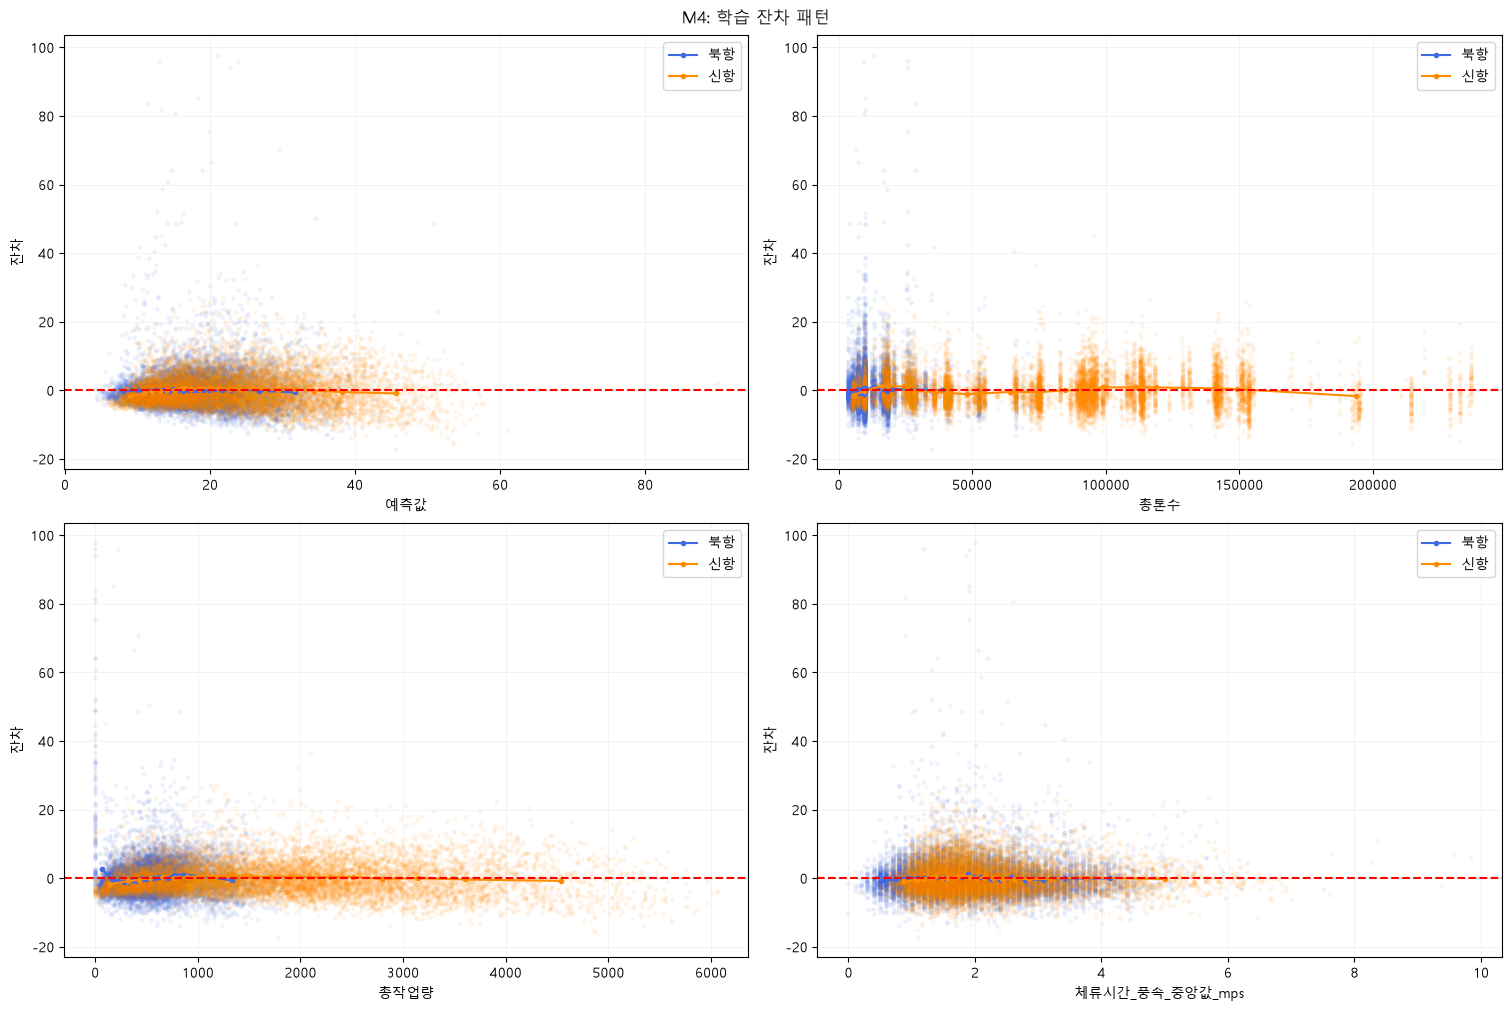

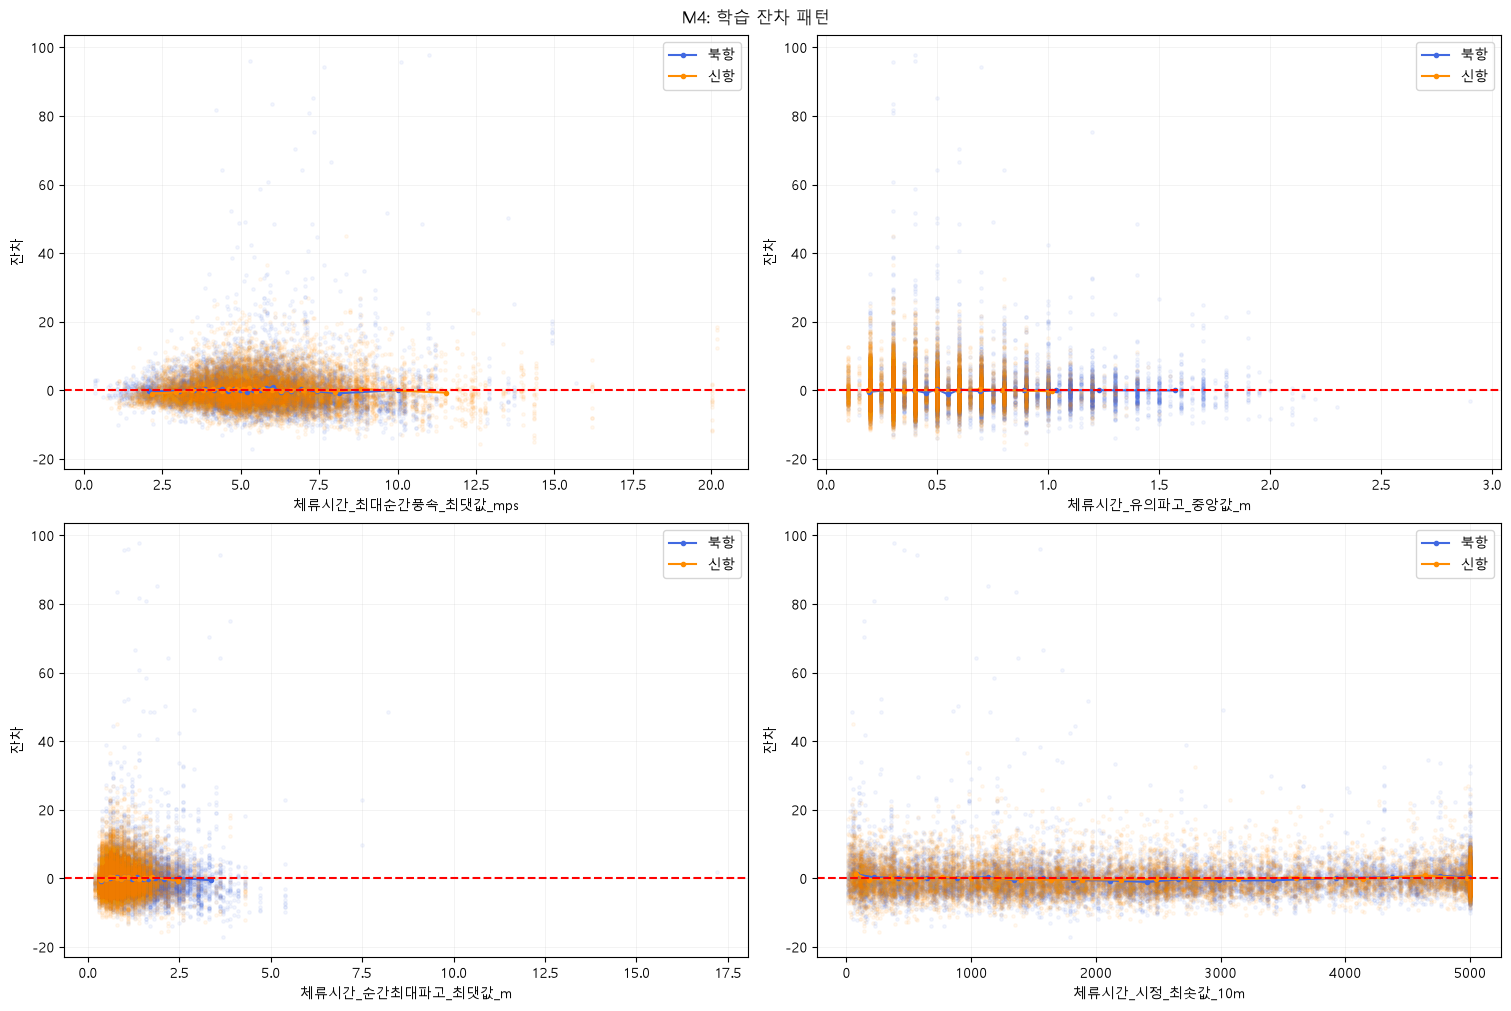

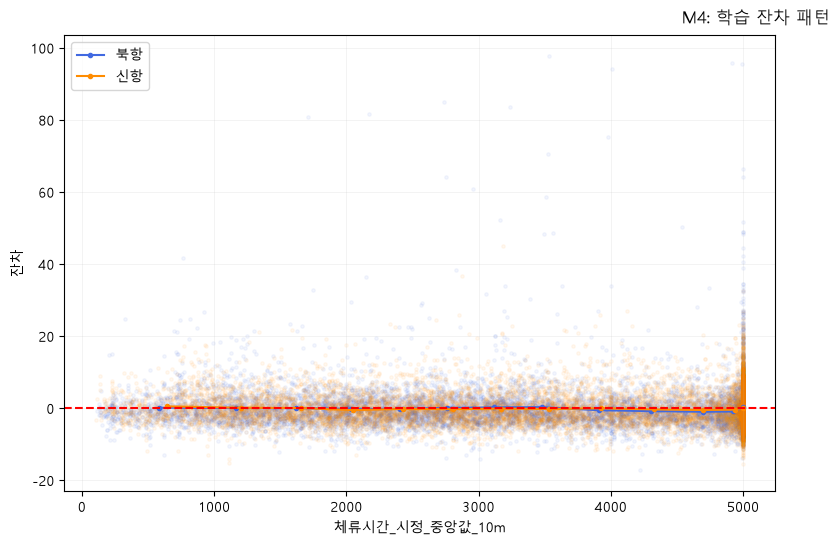

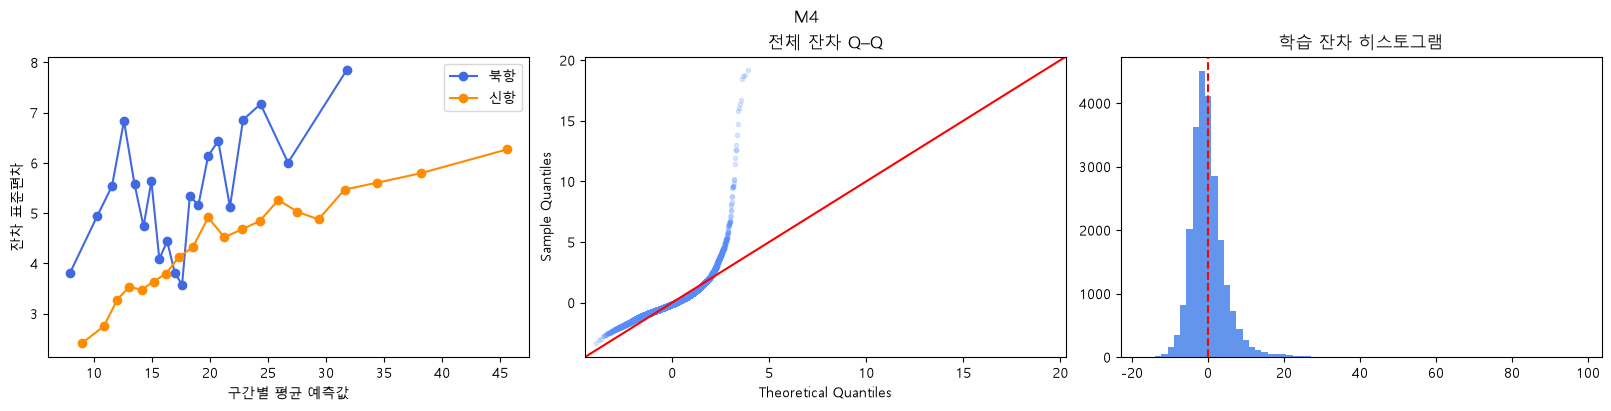

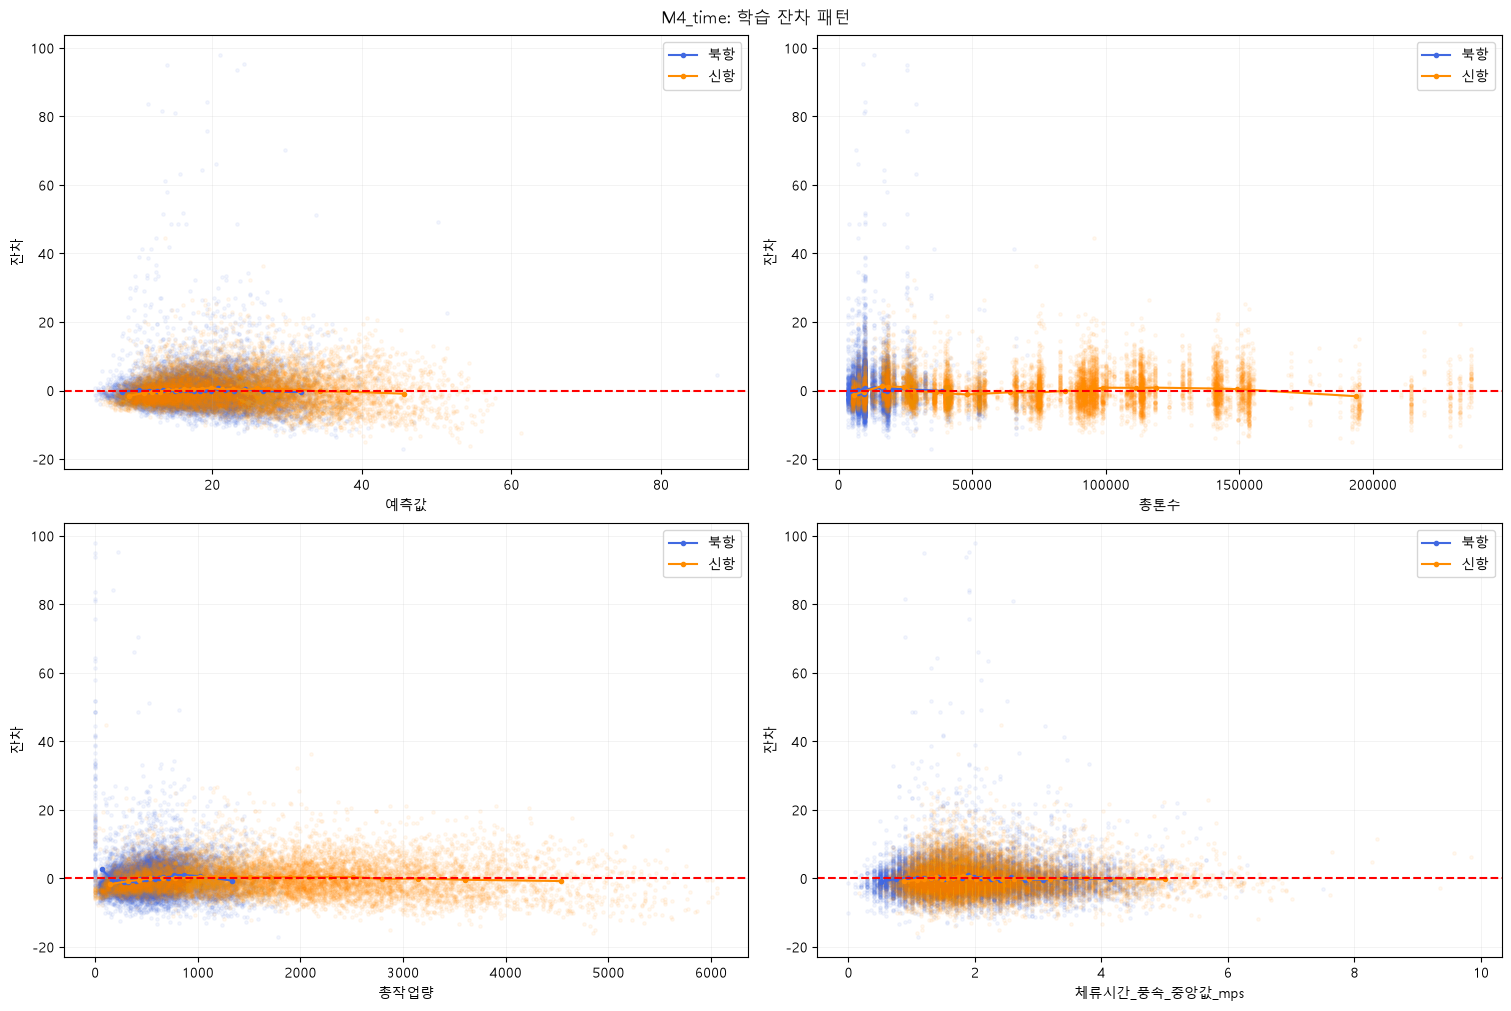

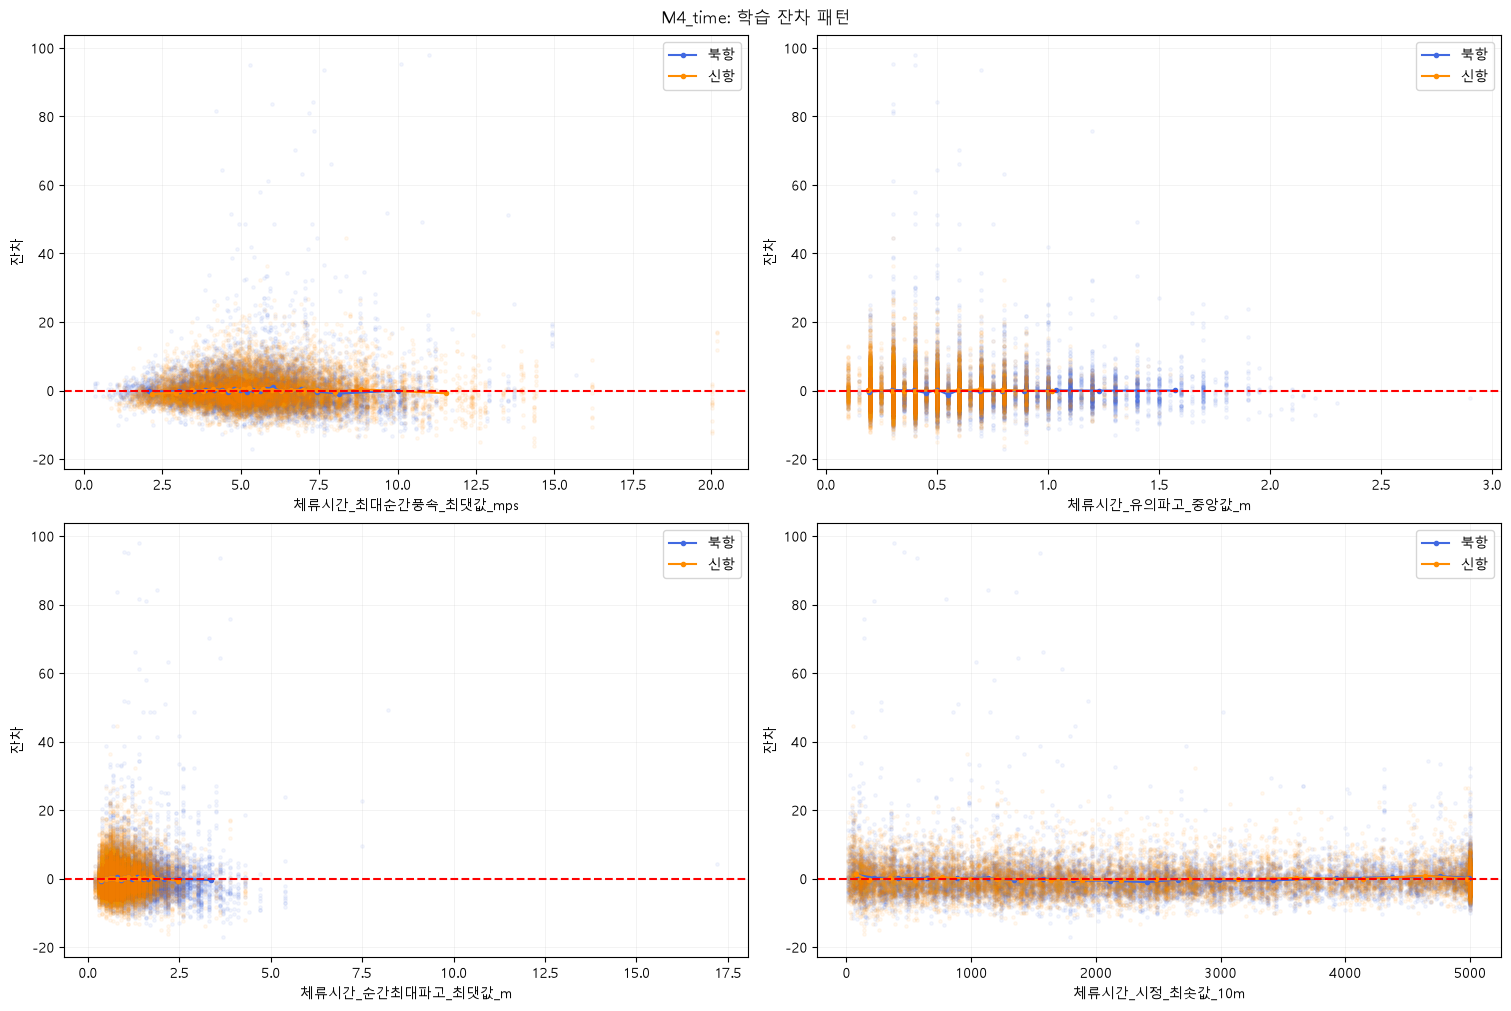

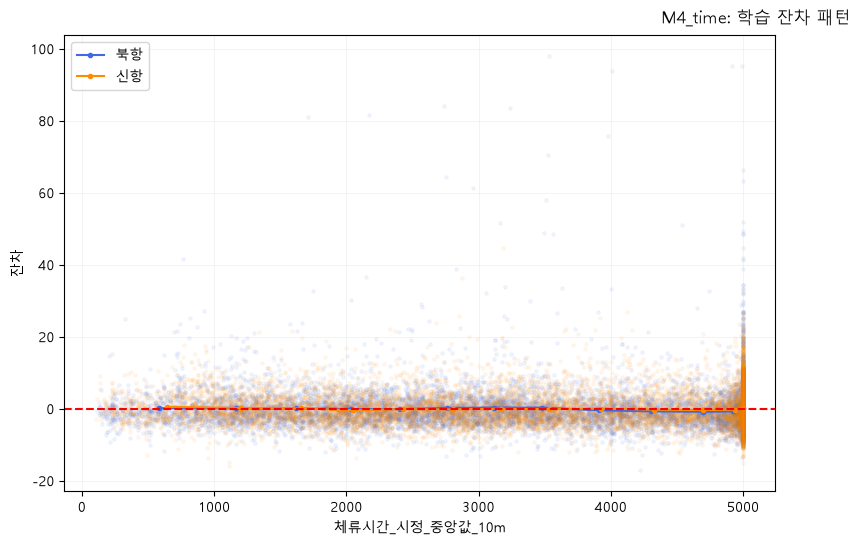

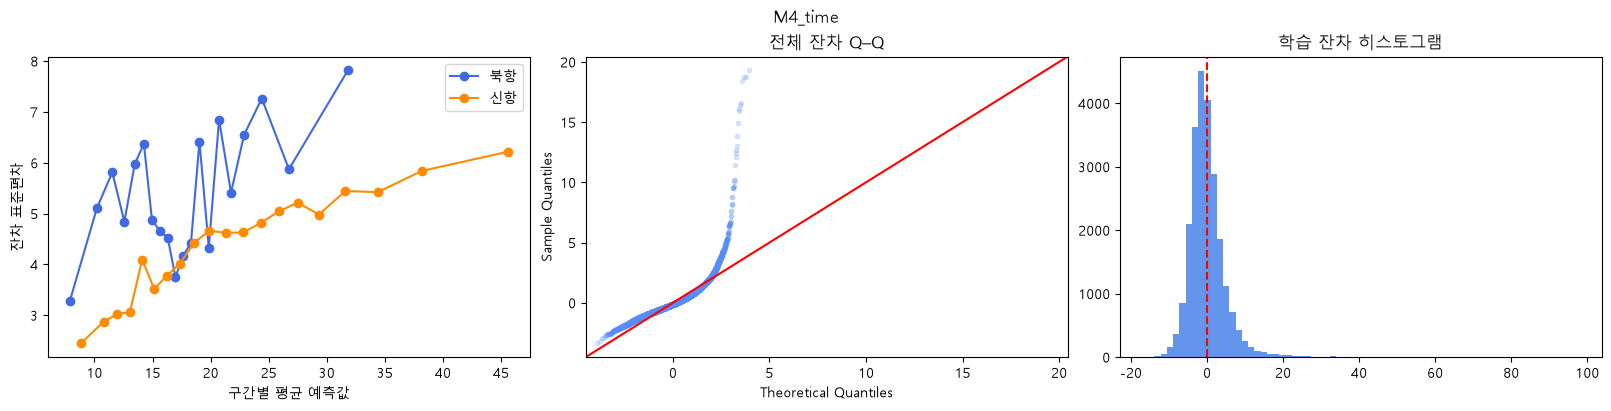

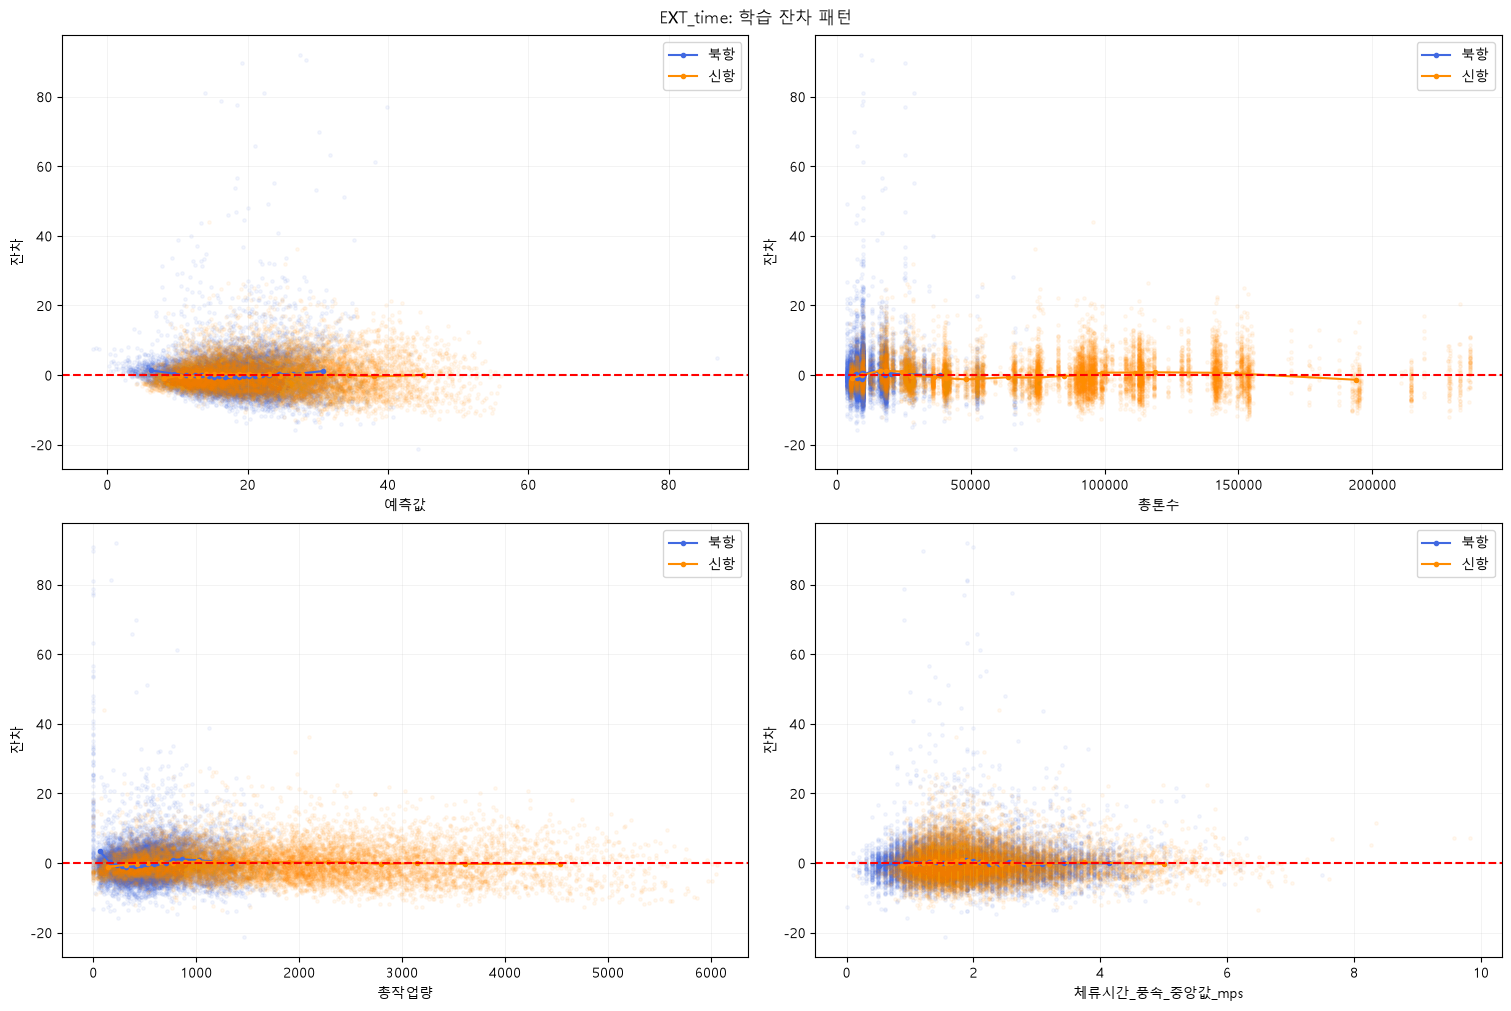

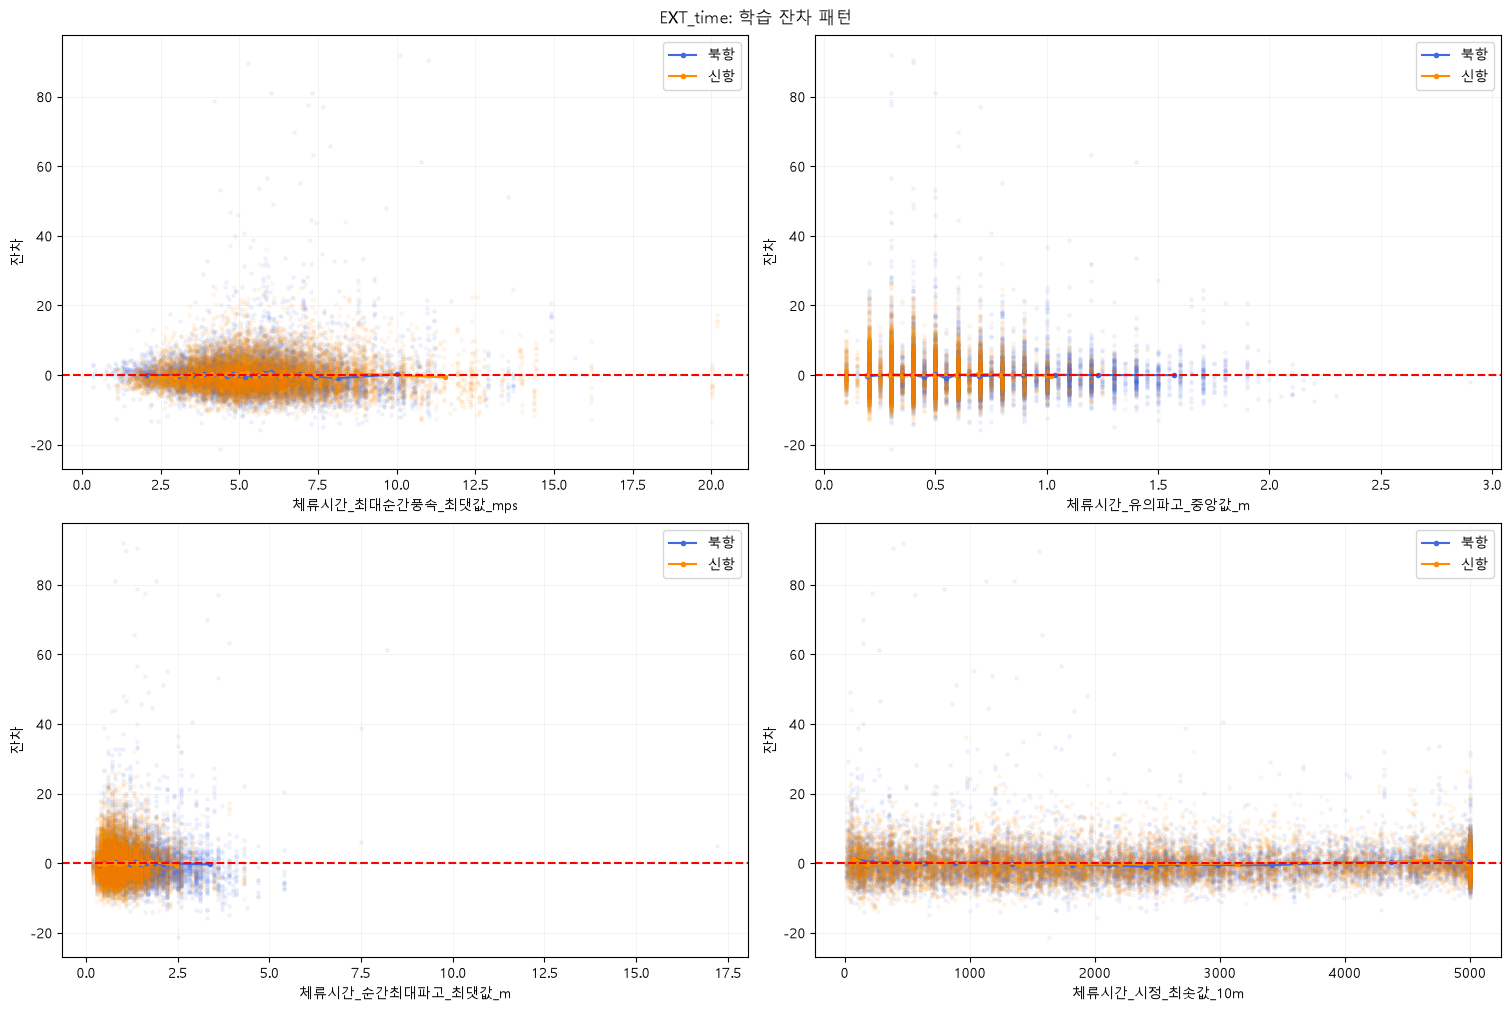

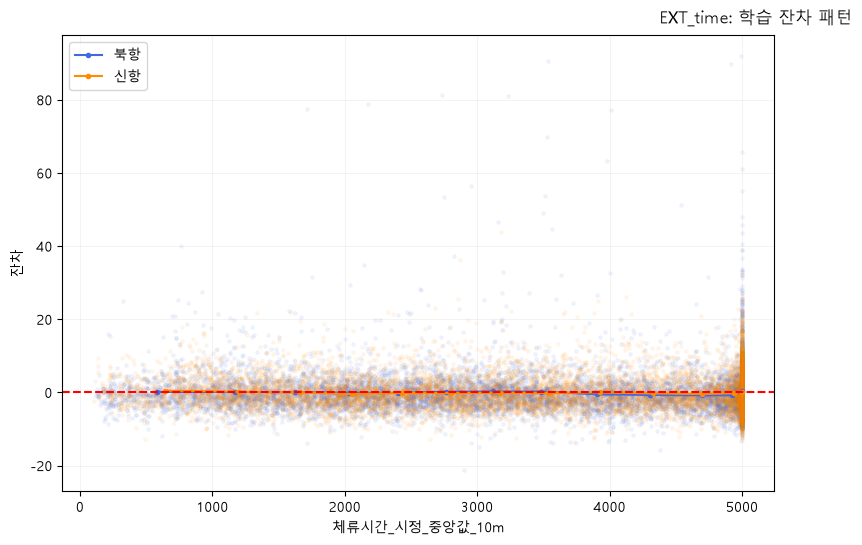

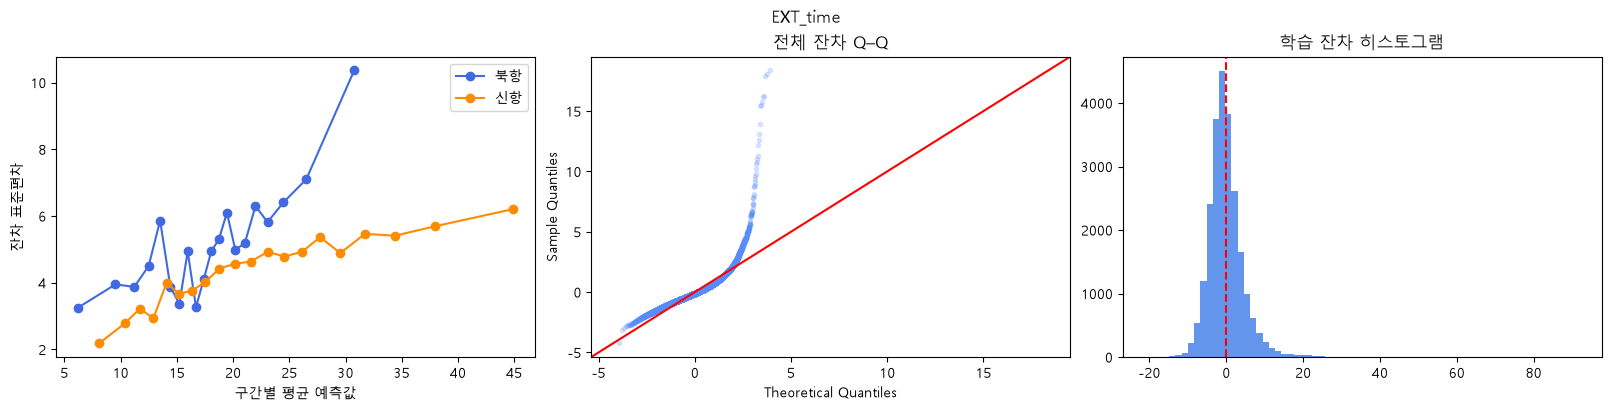

In [26]:
for name in DETAIL_MODELS:
    part = residual_data[name]
    plot_grid(part, ['예측값', '총톤수', '총작업량'] + weather6,
              '잔차', f'{name}: 학습 잔차 패턴', zero=True)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout='constrained')
    for port, color in colors.items():
        p = part.loc[part['항만구분'].eq(port)]
        bins = pd.qcut(p['예측값'], 20, duplicates='drop')
        spread = p.groupby(bins, observed=True).agg(x=('예측값', 'mean'), sd=('잔차', 'std'), n=('잔차', 'size'))
        axes[0].plot(spread.x, spread.sd, marker='o', label=port, color=color)
    axes[0].set(xlabel='구간별 평균 예측값', ylabel='잔차 표준편차')
    axes[0].legend()
    sm.qqplot(part['잔차'], fit=True, line='45', ax=axes[1], marker='.', alpha=0.2)
    axes[1].set_title('전체 잔차 Q–Q')
    axes[2].hist(part['잔차'], bins=70, color='cornflowerblue')
    axes[2].axvline(0, color='red', linestyle='--')
    axes[2].set_title('학습 잔차 히스토그램')
    fig.suptitle(name)
    plt.show()

### 6-3. 시간 및 집단별 의존성
터미널은 이번 회귀의 구분변수가 아니지만 항만 내부의 미설명 차이와 의존성을 찾는 진단 단위다.
항만 평균 잔차가 0인 것은 항만 절편이 들어간 OLS의 성질일 수 있어 적합성의 충분한 증거가 아니다.

DW·Ljung–Box·ACF는 **터미널별 접안 기록 순서**에서 계산한다. 불규칙한 시간 간격이므로
시차 1은 1시간·1일이 아니다. 동일시각의 순서는 행ID로 고정한다. 이 검정만으로 정확한 시간 상관구조를 확정하지 않는다.

,모형,터미널,표본 수,DW,기록 시차,LB 통계량,LB p값
0,M1,BNCT,2470,1.590002,1,63.146980,1.918434e-15
1,M1,BNCT,2470,1.590002,5,117.068545,1.310535e-23
2,M1,BNCT,2470,1.590002,10,147.974198,9.727869e-27
3,M1,BNCT,2470,1.590002,20,254.879867,1.183207e-42
4,M1,BPTC_G,4281,1.797362,1,36.579833,1.465400e-09
...,...,...,...,...,...,...,...
163,EXT_time,PNC,4855,1.375057,20,664.143550,8.438803e-128
164,EXT_time,PNIT,2260,1.631789,1,74.588884,5.796870e-18
165,EXT_time,PNIT,2260,1.631789,5,151.218881,7.346020e-31
166,EXT_time,PNIT,2260,1.631789,10,233.115718,1.907880e-44


M4 터미널별 잔차


,count,mean,std
터미널,,,
BNCT,2470,2.963699,4.598774
BPTC_G,4281,-0.753611,6.923911
BPT_S,7661,0.421121,4.601334
HPNT,2030,-0.404097,4.585035
PNC,4855,-1.454140,3.500153
PNIT,2260,0.247712,5.015840


,count,mean,std
특보유무,,,
0.0,20764,7.334530e-15,4.821841
1.0,2793,3.361150e-14,6.876277


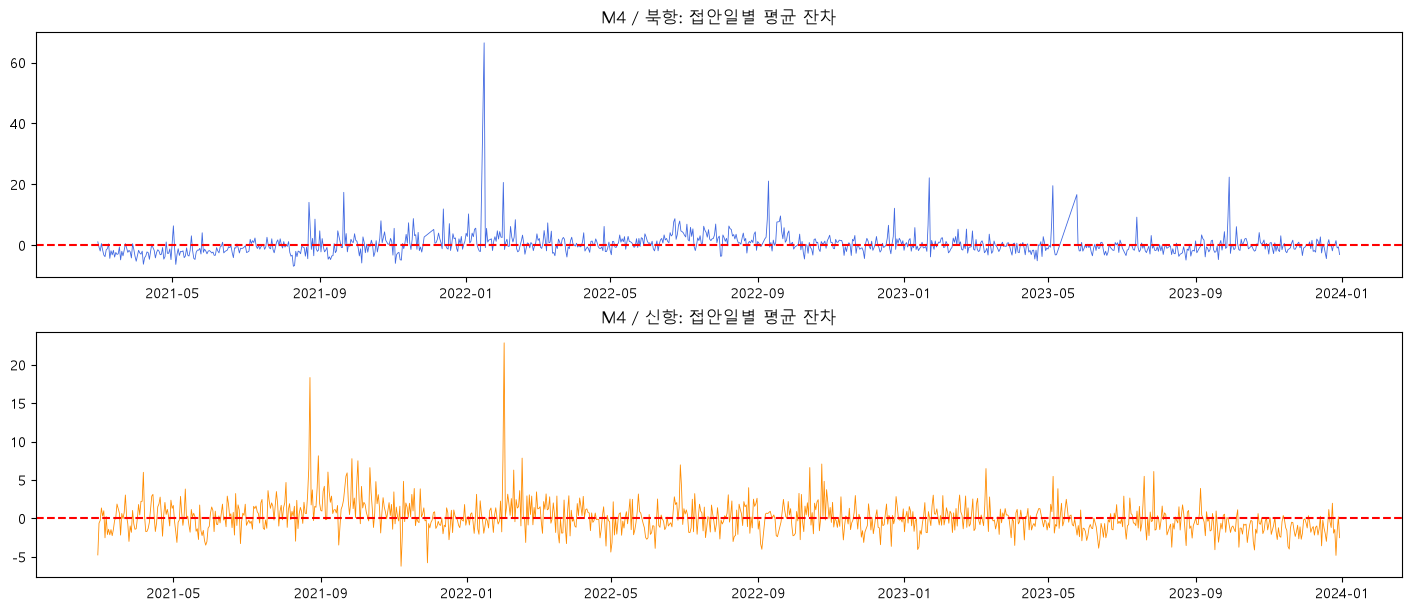

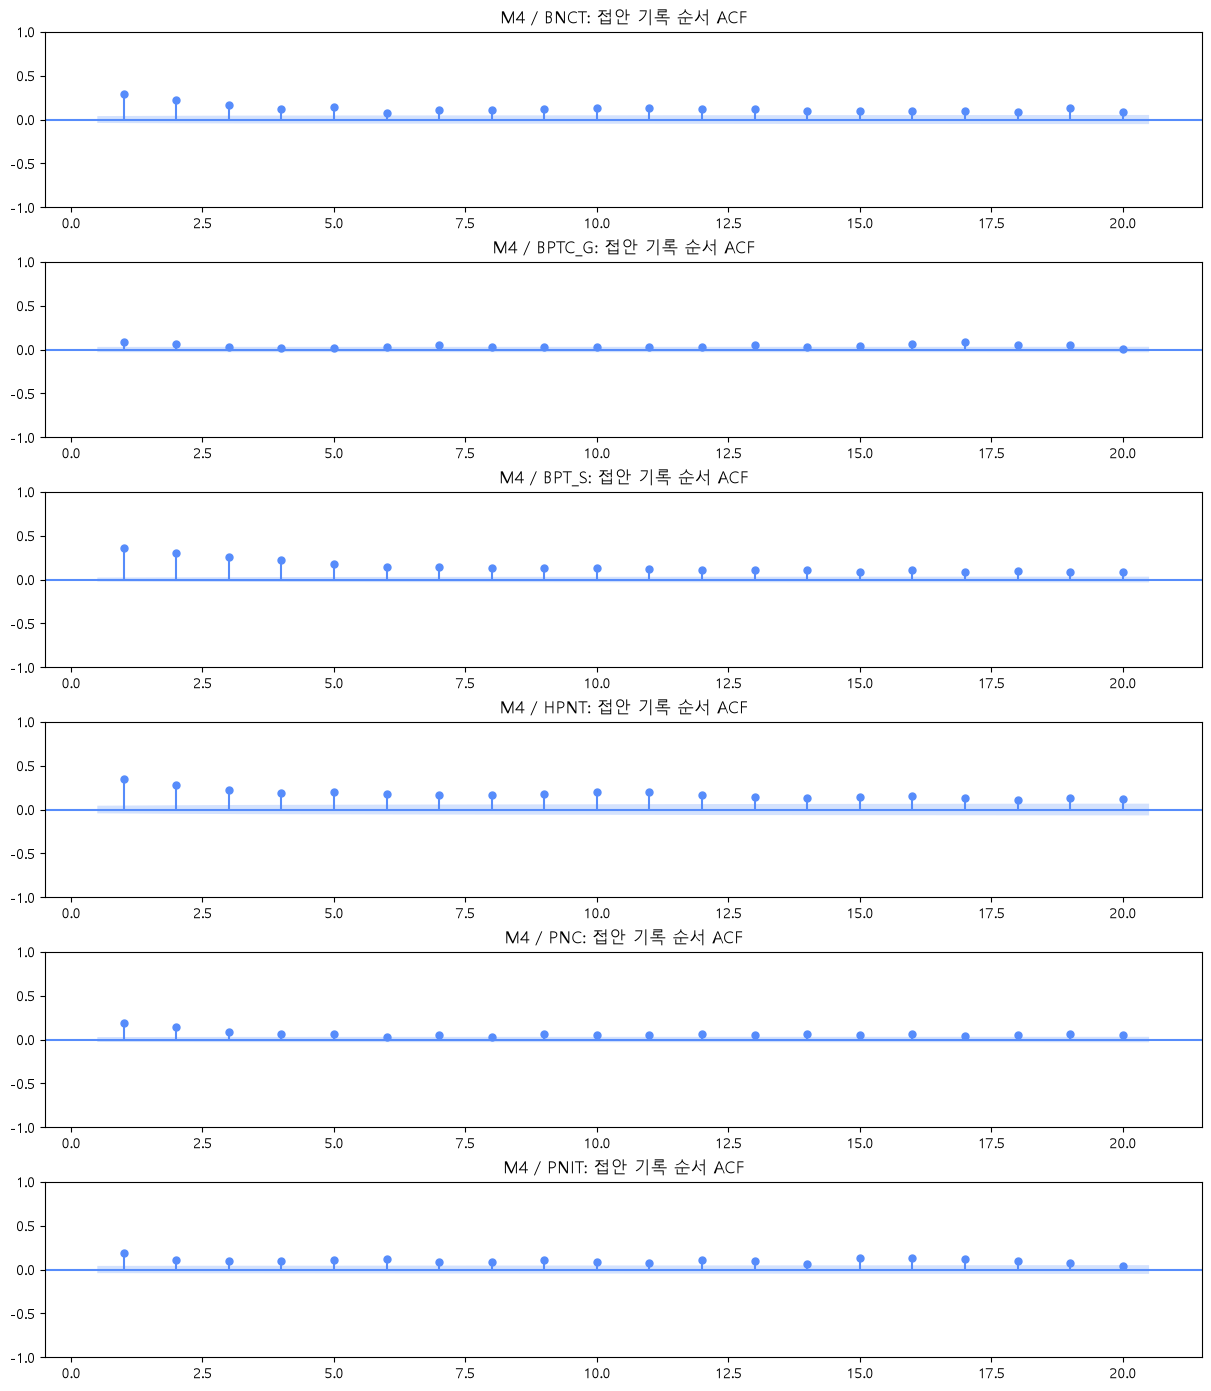

M4_time 터미널별 잔차


,count,mean,std
터미널,,,
BNCT,2470,2.946605,4.556928
BPTC_G,4281,-0.762311,6.881500
BPT_S,7661,0.425983,4.576287
HPNT,2030,-0.376156,4.514089
PNC,4855,-1.455306,3.508495
PNIT,2260,0.243801,4.987944


,count,mean,std
특보유무,,,
0.0,20764,-6.347943e-14,4.791384
1.0,2793,5.565727e-14,6.850615


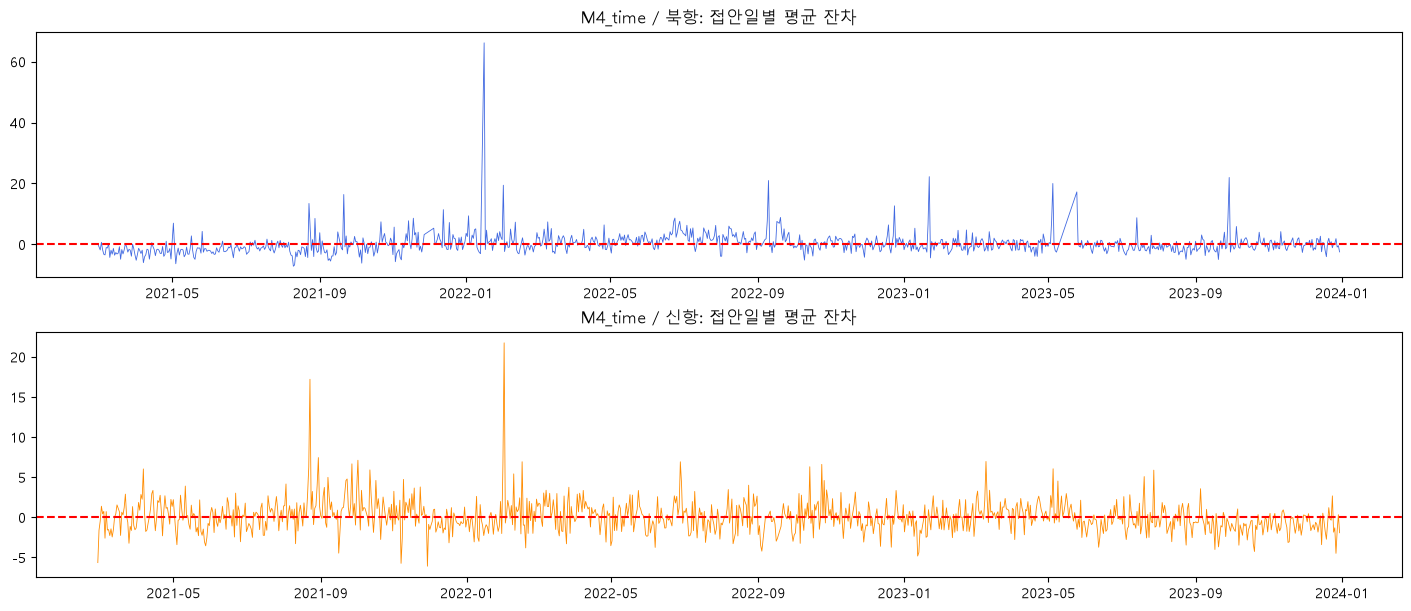

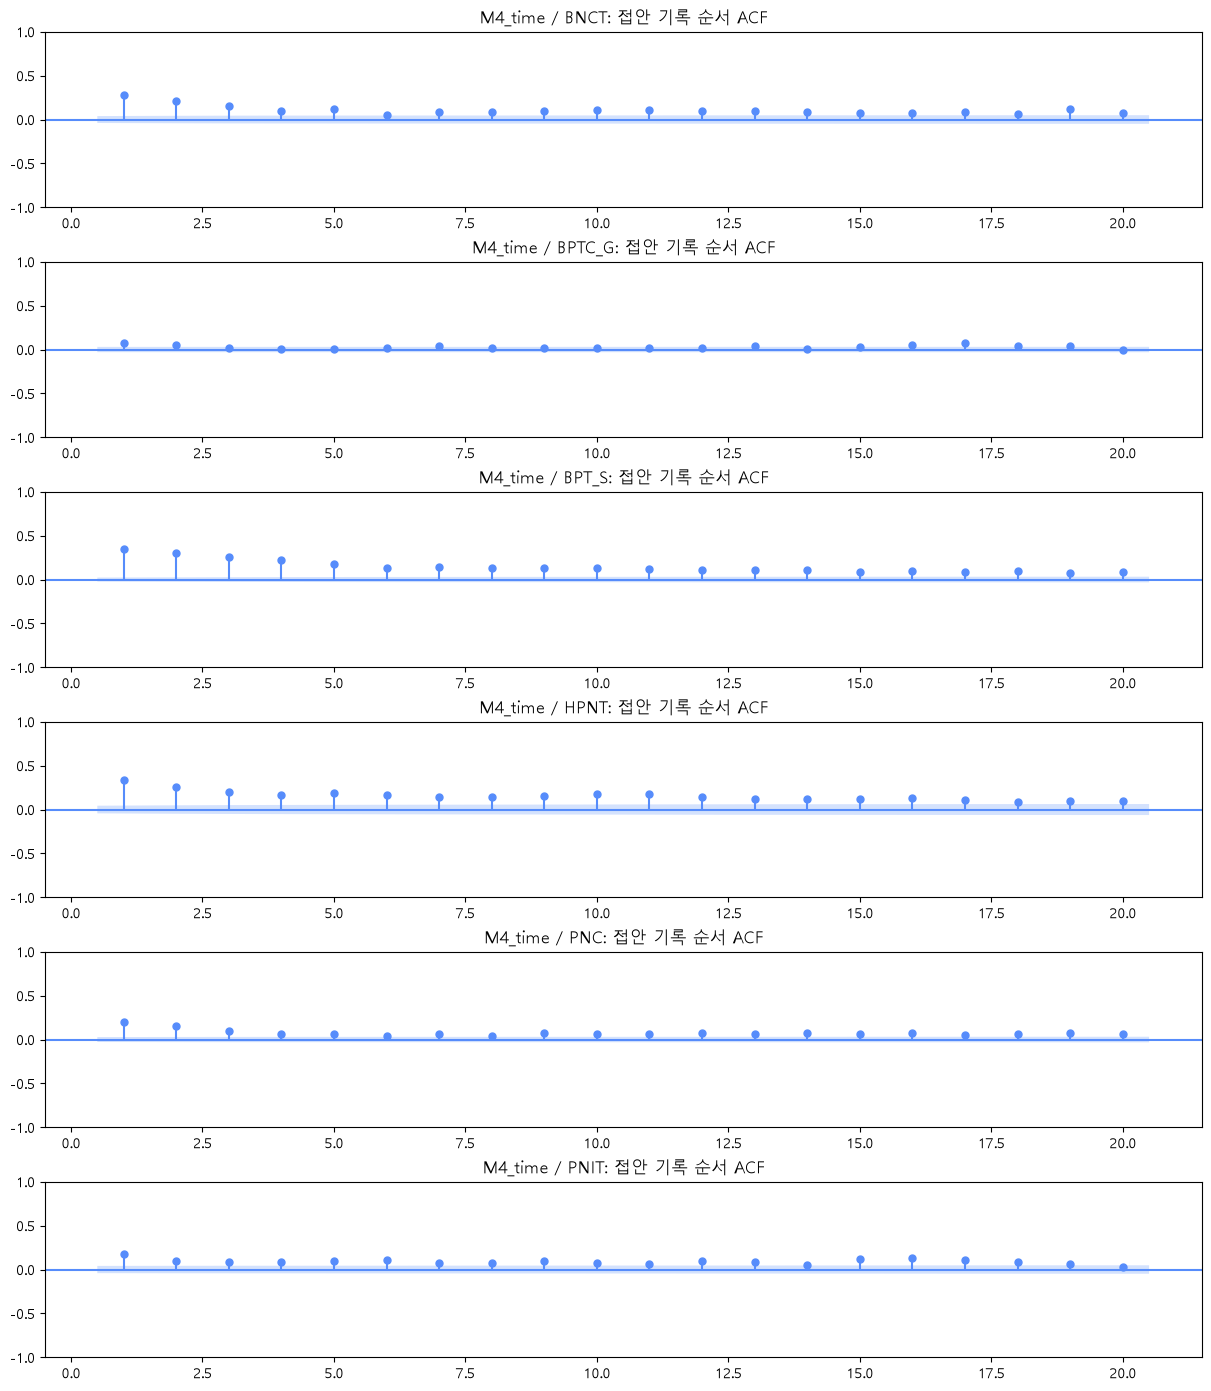

EXT_time 터미널별 잔차


,count,mean,std
터미널,,,
BNCT,2470,2.883598,4.529171
BPTC_G,4281,-0.750454,6.652360
BPT_S,7661,0.419357,4.573783
HPNT,2030,-0.390110,4.491654
PNC,4855,-1.425817,3.484324
PNIT,2260,0.261848,4.978227


,count,mean,std
특보유무,,,
0.0,20764,-5.385927e-14,4.732976
1.0,2793,2.832122e-15,6.708843


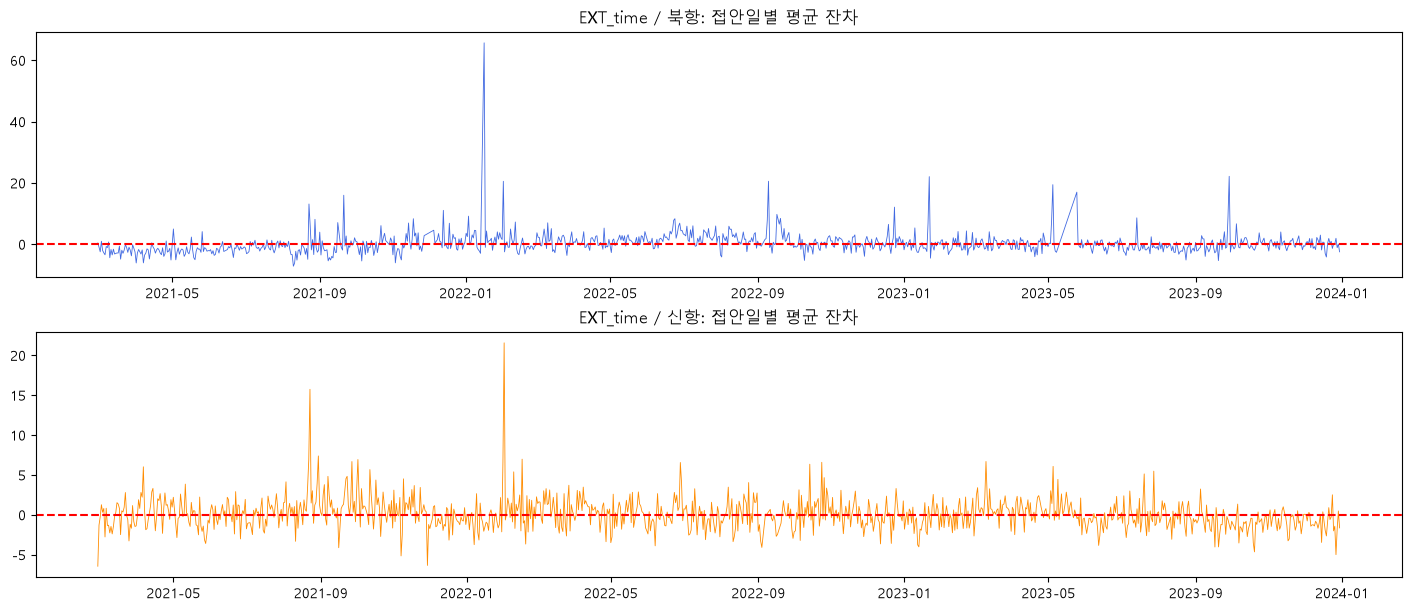

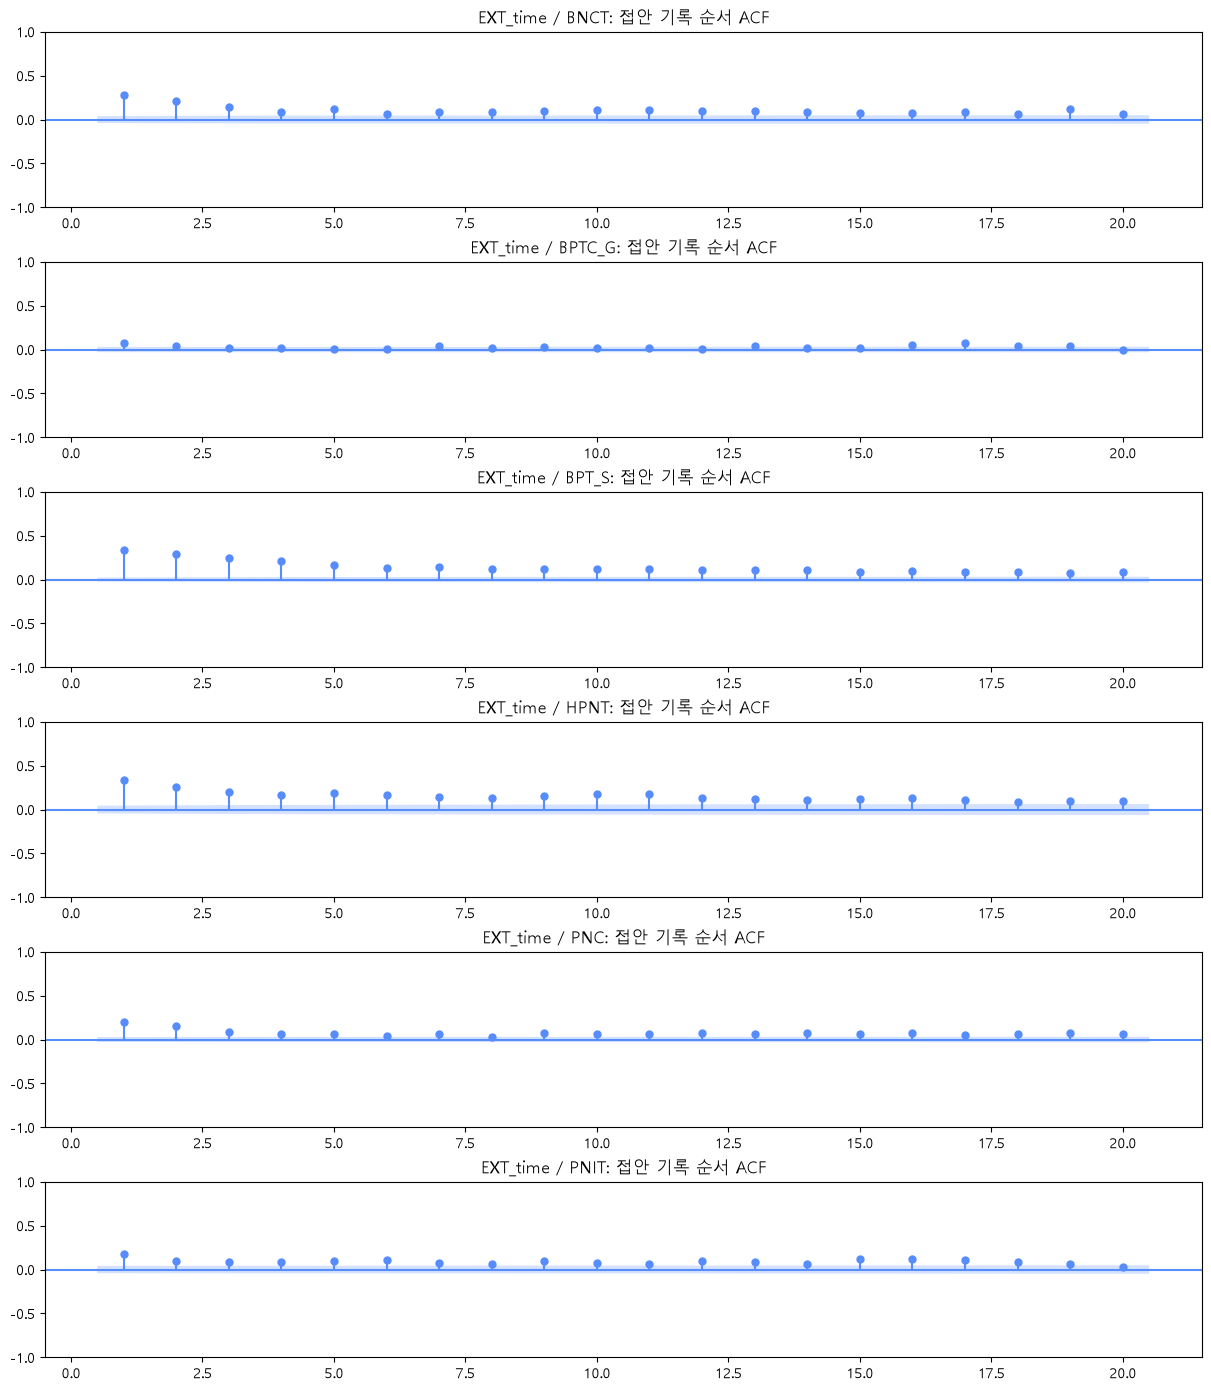

In [27]:
dependence_rows = []
for name, part in residual_data.items():
    for terminal, p in part.groupby('터미널'):
        p = p.sort_values(['접안일시', '행ID'])
        e = p['잔차'].to_numpy()
        lags = [k for k in [1, 5, 10, 20] if k < len(e)//5]
        if not lags:
            continue
        lb = acorr_ljungbox(e, lags=lags, return_df=True)
        for lag in lags:
            dependence_rows.append([name, terminal, len(e), durbin_watson(e), lag,
                                    lb.loc[lag, 'lb_stat'], lb.loc[lag, 'lb_pvalue']])
dependence = pd.DataFrame(dependence_rows, columns=['모형', '터미널', '표본 수', 'DW', '기록 시차', 'LB 통계량', 'LB p값'])
display(dependence)
for name in DETAIL_MODELS:
    part = residual_data[name]
    print(name, '터미널별 잔차')
    display(part.groupby('터미널')['잔차'].agg(['count', 'mean', 'std']))
    display(part.groupby('특보유무')['잔차'].agg(['count', 'mean', 'std']))
    fig, axes = plt.subplots(2, 1, figsize=(14, 6), layout='constrained')
    for ax, (port, color) in zip(axes, colors.items()):
        daily = part.loc[part['항만구분'].eq(port)].groupby(part['접안일시'].dt.floor('D'))['잔차'].mean()
        ax.plot(daily.index, daily, color=color, linewidth=0.6)
        ax.axhline(0, color='red', linestyle='--')
        ax.set_title(f'{name} / {port}: 접안일별 평균 잔차')
    plt.show()
    terminals = sorted(part['터미널'].unique())
    fig, axes = plt.subplots(len(terminals), 1, figsize=(12, 2.3*len(terminals)), layout='constrained')
    for ax, terminal in zip(np.atleast_1d(axes), terminals):
        e = part.loc[part['터미널'].eq(terminal)].sort_values(['접안일시', '행ID'])['잔차']
        plot_acf(e, lags=min(20, len(e)//5), zero=False, ax=ax)
        ax.set_title(f'{name} / {terminal}: 접안 기록 순서 ACF')
    plt.show()

### 6-4. 실제 모형의 VIF와 항만 내부 VIF
전체 행렬 VIF는 항만 상호작용과 월·요일·추세를 포함한다. 큰 값만 보고 자동 삭제하지 않는다.
항만 내부에서도 확장항과 시간항을 유지해 확인한다. 항만별로 상수인 열은 제외한다.
일반 개별열 VIF이므로 월·요일 묶음 전체의 GVIF와는 다르다.

In [28]:
port_final_vifs = []
for name, x in designs.items():
    print(name, '전체 행렬 VIF 상위 10개')
    display(final_vifs[name].head(10).round(3))
    for port in colors:
        part = x.loc[train['항만구분'].eq(port)]
        # D×X는 신항 내부에서 X와 동일하므로 중복 표현을 제거한다.
        columns = [c for c in part if c != 'const' and not c.startswith('신항더미 ×') and c != '신항더미']
        table = vif_table(part[columns])
        table['모형'], table['항만'] = name, port
        port_final_vifs.append(table)
port_final_vif = pd.concat(port_final_vifs, ignore_index=True)
display(port_final_vif.pivot(index=['모형', '변수'], columns='항만', values='VIF').round(3))

M1 전체 행렬 VIF 상위 10개


,변수,VIF
0,신항더미,1.0


M2 전체 행렬 VIF 상위 10개


,변수,VIF
0,총톤수,93.743
1,신항더미 × 총톤수,66.588
2,총작업량,30.196
3,신항더미 × 총작업량,24.415
4,신항더미,8.285


M3 전체 행렬 VIF 상위 10개


,변수,VIF
0,총톤수,93.743
1,신항더미 × 총톤수,66.588
2,총작업량,30.213
3,신항더미 × 총작업량,24.435
4,신항더미,8.428
5,신항더미 × 특보유무,2.248
6,특보유무,2.090


... (5 outputs left out)

,변수,VIF
0,총톤수 × 체류시간_최대순간풍속_최댓값_mps,314.597
1,신항더미 × 총톤수 × 체류시간_최대순간풍속_최댓값_mps,273.005
2,총톤수 × 체류시간_순간최대파고_최댓값_m,246.257
3,총톤수 × 특보유무,212.105
4,총톤수 × 체류시간_풍속_중앙값_mps,208.357
5,총톤수 × 체류시간_유의파고_중앙값_m,204.505
6,총톤수 × 체류시간_시정_최솟값_10m,196.884
7,총톤수 × 체류시간_시정_중앙값_10m,186.860
8,신항더미 × 총톤수 × 특보유무,178.653
9,신항더미 × 총톤수 × 체류시간_순간최대파고_최댓값_m,170.871


EXT_time 전체 행렬 VIF 상위 10개


,변수,VIF
0,총톤수 × 체류시간_최대순간풍속_최댓값_mps,314.912
1,신항더미 × 총톤수 × 체류시간_최대순간풍속_최댓값_mps,273.272
2,총톤수 × 체류시간_순간최대파고_최댓값_m,246.421
3,총톤수 × 특보유무,212.254
4,총톤수 × 체류시간_풍속_중앙값_mps,208.655
5,총톤수 × 체류시간_유의파고_중앙값_m,204.648
6,총톤수 × 체류시간_시정_최솟값_10m,197.008
7,총톤수 × 체류시간_시정_중앙값_10m,187.023
8,신항더미 × 총톤수 × 특보유무,178.784
9,신항더미 × 총톤수 × 체류시간_순간최대파고_최댓값_m,170.989


항만                               북항     신항
모형      변수                                
EXT     체류시간_순간최대파고_최댓값_m    63.261  4.556
        체류시간_시정_중앙값_10m      31.807  3.145
        체류시간_시정_최솟값_10m      33.047  3.227
        체류시간_유의파고_중앙값_m      63.222  4.041
        체류시간_최대순간풍속_최댓값_mps  37.681  3.310
...                             ...    ...
M4_time 체류시간_최대순간풍속_최댓값_mps   2.597  2.574
        체류시간_풍속_중앙값_mps       2.325  2.172
        총작업량                  1.488  2.443
        총톤수                   1.325  2.149
        특보유무                  1.682  1.648

[105 rows x 2 columns]

## 7. 검증자료 성능 비교
모든 후보를 같은 2024년 행에서 시간 단위로 평가한다. 평균 오차는 실제값−예측값이므로
양수면 평균적으로 과소예측이다. 검증 R²는 음수가 될 수도 있다.
항만×특보, 월, 체류시간 상위 10% 집단도 본다. 상위 10% 기준은 학습자료에서 고정한다.
층별 표본 수가 적으면 오차 차이도 불안정하다. 후보별 상세 행 오차를 저장한다.

In [29]:
def metrics(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    e = actual-predicted
    den = np.sum((actual-actual.mean())**2)
    return {'표본 수': len(e), 'MAE': np.mean(np.abs(e)),
            'RMSE': np.sqrt(np.mean(e**2)), '평균 오차': np.mean(e),
            '검증 R²': 1-np.sum(e**2)/den if den > 0 else np.nan}

evaluation_rows, error_frames = [], []
long_cut = train['체류시간'].quantile(0.9)
for name, pred in predictions.items():
    p = test[['행ID', '체류시간', '항만구분', '특보유무', '월', '터미널']].copy()
    p['예측값'] = np.asarray(pred)
    p['잔차'] = p['체류시간']-p['예측값']
    p['모형'] = name
    error_frames.append(p)
    groups = [('전체', '전체', p)]
    for col in ['항만구분', '특보유무', '월', '터미널']:
        groups += [(col, str(g), q) for g, q in p.groupby(col)]
    groups += [('항만×특보', str(g), q) for g, q in p.groupby(['항만구분', '특보유무'])]
    groups += [('장기 체류', f'학습 90분위 이상: {long_cut:.2f}시간', p.loc[p['체류시간'].ge(long_cut)])]
    for kind, group, q in groups:
        if len(q):
            evaluation_rows.append({'모형': name, '구분': kind, '집단': group,
                                    **metrics(q['체류시간'], q['예측값'])})
evaluation = pd.DataFrame(evaluation_rows)
test_errors = pd.concat(error_frames, ignore_index=True)
overall = evaluation.query("구분 == '전체'").set_index('모형')
comparison = fit_summary.join(overall[['MAE', 'RMSE', '평균 오차', '검증 R²']]).join(diagnostics)
display(comparison.round(4))
display(evaluation.loc[evaluation['구분'].isin(['항만×특보', '장기 체류'])].round(4))
comparison.to_csv(OUTPUT / '후보_공통비교.csv', encoding='utf-8-sig')
evaluation.to_csv(OUTPUT / '검증_집단별오차.csv', index=False, encoding='utf-8-sig')
test_errors.to_csv(OUTPUT / '검증_개별예측.csv', index=False, encoding='utf-8-sig')
dependence.to_csv(OUTPUT / '터미널_기록순서_자기상관.csv', index=False, encoding='utf-8-sig')

,학습 표본 수,계수 수,학습 R²,학습 수정 R²,AIC,BIC,MAE,RMSE,평균 오차,검증 R²,BP p값,잔차 왜도,실제 행렬 최대 VIF,최대 Cook 거리,Cook>4/n 개수
모형,,,,,,,,,,,,,,,
M1,23557,2,0.0542,0.0542,172384.7515,172400.8858,6.5583,8.5030,-0.0482,0.0887,0.0,1.2583,1.0000,0.0049,1011
M2,23557,6,0.6723,0.6722,147425.5588,147473.9619,3.5212,4.6923,-0.9687,0.7225,0.0,4.7012,93.7432,0.0875,1162
M3,23557,8,0.6770,0.6770,147084.3204,147148.8578,3.5403,4.6952,-1.0980,0.7221,0.0,4.6283,93.7434,0.0873,1209
M4,23557,20,0.7202,0.7200,143730.2105,143891.5540,3.2303,4.3625,-0.7772,0.7601,0.0,3.9979,94.2061,0.0862,1105
M4_time,23557,38,0.7234,0.7230,143494.0032,143800.5560,3.1130,4.2787,-0.2156,0.7692,0.0,4.0058,94.6435,0.0511,990
EXT,23557,48,0.7280,0.7275,143116.5845,143503.8090,3.2418,4.3768,-0.8093,0.7585,0.0,3.5829,314.5970,0.2236,1267
EXT_time,23557,66,0.7311,0.7304,142884.9026,143417.3364,3.1234,4.2900,-0.2796,0.7680,0.0,3.5871,314.9120,0.1656,1189


,모형,구분,집단,표본 수,MAE,RMSE,평균 오차,검증 R²
23,M1,항만×특보,"('북항', 0.0)",3677,4.9996,6.4655,-0.9245,-0.0209
24,M1,항만×특보,"('북항', 1.0)",774,5.6553,7.6730,1.6956,-0.0513
25,M1,항만×특보,"('신항', 0.0)",3189,8.0091,9.9128,-0.2163,-0.0005
26,M1,항만×특보,"('신항', 1.0)",802,8.8073,11.0388,2.9549,-0.0772
27,M1,장기 체류,학습 90분위 이상: 33.00시간,786,17.7992,18.7275,17.7992,-9.6931
51,M2,항만×특보,"('북항', 0.0)",3677,3.6237,4.7592,-2.0362,0.4469
52,M2,항만×특보,"('북항', 1.0)",774,3.9516,5.5329,-0.1110,0.4533
53,M2,항만×특보,"('신항', 0.0)",3189,3.2833,4.3461,-0.3034,0.8077
54,M2,항만×특보,"('신항', 1.0)",802,3.5815,4.8235,0.4518,0.7943
55,M2,장기 체류,학습 90분위 이상: 33.00시간,786,6.3864,8.8618,3.4086,-1.3944


## 8. 특보 KPI 안정성 비교
### 8-1. 계산식과 불확실성
각 기록의 특보만 0/1로 바꾸고 모든 상호작용을 다시 만든다.

**KPI(x) = 예측 체류시간(A=1,x) − 예측 체류시간(A=0,x)**

음수 결과도 그대로 표시하고 0으로 잘라내지 않는다. 실제 개별 지연이나 인과효과가 아니라
다른 조건을 고정한 모형상 연관 차이이다. 특보와 기상은 관련되어 있어 일부 전환 조합은 현실에 드물 수 있다.
따라서 특보 집단별 실제 예측오차와 함께 해석한다. M1/M2에는 특보항이 없으므로 KPI 비교에서 제외한다.

선박 반복과 같은 시기 공통 충격을 고려하려고 선박·시간블록 이중 군집 공분산을 계산한다.
7·14·28일 블록 모두 확인하며 유리한 결과만 고르지 않는다. 블록 밖 시간 의존성을 완전히 해결하는 방법은 아니다.
구간은 조건부 **평균 차이의 근사 신뢰구간**이며 개인 체류시간 예측구간이 아니다.
두 방향 군집 추정은 유한표본에서 비양정치일 수 있어 음의 추정분산은 NaN으로 표시하고 경고한다.

In [30]:
def kpi_contrast(frame, spec):
    return make_design(frame, spec, alert=1)-make_design(frame, spec, alert=0)

def clustered_cov(model, frame, days):
    ship = pd.factorize(frame['선박명'])[0]
    block = ((frame['접안일시']-pd.Timestamp('2021-01-01')).dt.days // days).to_numpy()
    covariance, _, _ = cov_cluster_2groups(model, ship, block, use_correction=True)
    return covariance

kpi_rows = []
kpi_individual = []
for name, model in models.items():
    if specs[name]['stage'] < 3:
        continue
    contrast = kpi_contrast(test, specs[name])
    delta = contrast.to_numpy() @ model.params.to_numpy()
    direct = model.predict(make_design(test, specs[name], alert=1))-model.predict(make_design(test, specs[name], alert=0))
    assert np.allclose(delta, direct)
    one = test[['행ID', '항만구분', '총톤수', '총작업량', '특보유무']].copy()
    one['모형'], one['KPI 시간'] = name, delta
    kpi_individual.append(one)
    for days in [7, 14, 28]:
        covariance = clustered_cov(model, train, days)
        for port in colors:
            c = contrast.loc[test['항만구분'].eq(port)].mean().to_numpy()
            estimate = float(c @ model.params)
            variance = float(c @ covariance @ c)
            se = np.sqrt(variance) if variance >= 0 else np.nan
            kpi_rows.append([name, port, days, estimate, se,
                             estimate-1.96*se, estimate+1.96*se,
                             '분산 추정 재검토' if variance < 0 else '근사구간'])
kpi_summary = pd.DataFrame(kpi_rows, columns=[
    '모형', '항만', '시간블록 일수', '평균 KPI 시간', '표준오차', '95% 하한', '95% 상한', '상태'])
kpi_details = pd.concat(kpi_individual, ignore_index=True)
display(kpi_summary.round(4))
display(kpi_details.groupby(['모형', '항만구분'])['KPI 시간'].agg(['min', 'median', 'max']))
kpi_summary.to_csv(OUTPUT / '특보KPI_군집구간_민감도.csv', index=False, encoding='utf-8-sig')
kpi_details.to_csv(OUTPUT / '특보KPI_개별시나리오.csv', index=False, encoding='utf-8-sig')

,모형,항만,시간블록 일수,평균 KPI 시간,표준오차,95% 하한,95% 상한,상태
0,M3,북항,7,2.6827,0.5230,1.6576,3.7079,근사구간
1,M3,신항,7,1.2527,0.2460,0.7704,1.7349,근사구간
2,M3,북항,14,2.6827,0.5349,1.6343,3.7311,근사구간
3,M3,신항,14,1.2527,0.2707,0.7221,1.7833,근사구간
4,M3,북항,28,2.6827,0.5265,1.6508,3.7146,근사구간
5,M3,신항,28,1.2527,0.2489,0.7649,1.7405,근사구간
6,M4,북항,7,0.8624,0.4743,-0.0672,1.7921,근사구간
7,M4,신항,7,0.6225,0.2894,0.0553,1.1897,근사구간
8,M4,북항,14,0.8624,0.4979,-0.1134,1.8382,근사구간
9,M4,신항,14,0.6225,0.3020,0.0307,1.2144,근사구간


min    median       max
모형       항만구분                              
EXT      북항   -0.846944  0.930383  1.460922
         신항   -0.448048  0.639728  1.750800
EXT_time 북항   -0.623048  0.904378  1.459651
         신항   -0.578480  0.649293  1.851652
M3       북항    2.682728  2.682728  2.682728
         신항    1.252688  1.252688  1.252688
M4       북항    0.862404  0.862404  0.862404
         신항    0.622522  0.622522  0.622522
M4_time  북항    0.838857  0.838857  0.838857
         신항    0.618494  0.618494  0.618494

### 8-2. 학습기간 변경 시 계수·KPI 민감도
2021~2023년을 모두 사용한 결과와 각 연도를 하나씩 뺀 결과를 비교한다.
중심화·표준화 기준과 변수 구성은 기존 학습 기준을 유지하고, KPI는 같은 2024년 설명변수에 평균낸다.
이는 시간순 예측 검증이 아니라 학습기간 구성에 대한 민감도 분석이다.
미래 자료를 학습에 넣어 과거 예측 성능을 주장하지 않는다.

특보 0/1 집단에서 총톤수·작업량의 범위가 충분히 겹치는지도 확인한다.
범위 겹침만으로 조건부 비교의 타당성이 보장되지는 않는다.

In [31]:
stability_rows = []
for name in DETAIL_MODELS:
    contrast = kpi_contrast(test, specs[name])
    for dropped in [None, 2021, 2022, 2023]:
        subset = train if dropped is None else train.loc[train['접안일시'].dt.year.ne(dropped)]
        x = make_design(subset, specs[name])
        if np.linalg.matrix_rank(x.to_numpy()) < x.shape[1]:
            continue
        fit = sm.OLS(subset['체류시간'], x).fit()
        for port in colors:
            c = contrast.loc[test['항만구분'].eq(port)].mean().to_numpy()
            stability_rows.append([name, '전체 학습' if dropped is None else f'{dropped}년 제외',
                                   port, len(subset), float(c @ fit.params)])
stability = pd.DataFrame(stability_rows, columns=['모형', '학습 구성', '항만', '학습 표본 수', '평균 KPI 시간'])
display(stability.round(4))
display(train.groupby(['항만구분', '특보유무'])[['총톤수', '총작업량']].agg(['count', 'min', 'median', 'max']))
stability.to_csv(OUTPUT / '특보KPI_학습기간_민감도.csv', index=False, encoding='utf-8-sig')

,모형,학습 구성,항만,학습 표본 수,평균 KPI 시간
0,M4,전체 학습,북항,23557,0.8624
1,M4,전체 학습,신항,23557,0.6225
2,M4,2021년 제외,북항,16993,1.0122
3,M4,2021년 제외,신항,16993,0.6283
4,M4,2022년 제외,북항,15413,0.8896
5,M4,2022년 제외,신항,15413,0.8770
6,M4,2023년 제외,북항,14708,0.6300
7,M4,2023년 제외,신항,14708,0.1608
8,M4_time,전체 학습,북항,23557,0.8389
9,M4_time,전체 학습,신항,23557,0.6185


총톤수                              총작업량                     
           count     min   median       max  count  min  median     max
항만구분 특보유무                                                              
북항   0.0   10616  3736.0   9598.0   75488.0  10616  0.0   505.0  1832.0
     1.0    1326  3736.0   9858.0   73157.0   1326  0.0   534.5  1803.0
신항   0.0   10148  3994.0  69246.0  236583.0  10148  0.0  1365.0  6060.0
     1.0    1467  5403.0  87023.0  236583.0   1467  0.0  1771.0  5623.0

## 9. 최종 모형 선택과 근거
다음 표를 채운 뒤 아래 코드 셀의 `FINAL_MODEL`을 지정한다.
검증 RMSE 최저라는 이유만으로 자동 확정하지 않는다. 수치 차이가 작으면 단순한 모형을 고려한다.

| 판단 | 검토할 결과 |
|---|---|
| 전체·중요 집단 성능 | MAE, RMSE, 항만×특보 평균 오차, 장기 체류 과소예측 |
| 평균 관계 | 잔차–예측값·각 X의 곡선, 집단별 지속적 치우침 |
| 불확실성 | 이분산·의존성에 맞는 신뢰구간, 블록 길이별 민감도 |
| 특보 KPI | 부호·크기·신뢰구간·학습기간 변경 안정성, 조합의 관측 범위 |
| 복잡도 | 추가 상호작용의 실질적 이득, VIF·계수의 안정성 |

잔차 정규성만으로 모형을 탈락시키지 않으며, 실제 기상이변을 삭제해 정규성을 맞추지 않는다.
2024년에 맞춰 모형을 바꾸었다면 이후 독립 자료가 최종 확인에 필요하다.

In [33]:
print('검증 RMSE 기준 참고 순서 — 자동 최종 선택 아님')
display(comparison.sort_values('RMSE').round(4))

FINAL_MODEL = 'M4_time'
SELECTION_REASON = ("  2024년 검증 MAE·RMSE가 가장 작고, 확장 모형보다 적은 계수로 유사한 성능을 보여 선택하였다. "
    "이분산성·자기상관·장기 체류 과소예측이 남으며, 특보 KPI는 불확실성을 가진 항만별 시나리오 차이로 해석한다.")
if FINAL_MODEL is not None:
    assert FINAL_MODEL in specs
    print('선택한 모형:', FINAL_MODEL)
    print('선택 근거:', SELECTION_REASON)

검증 RMSE 기준 참고 순서 — 자동 최종 선택 아님


,학습 표본 수,계수 수,학습 R²,학습 수정 R²,AIC,BIC,MAE,RMSE,평균 오차,검증 R²,BP p값,잔차 왜도,실제 행렬 최대 VIF,최대 Cook 거리,Cook>4/n 개수
모형,,,,,,,,,,,,,,,
M4_time,23557,38,0.7234,0.7230,143494.0032,143800.5560,3.1130,4.2787,-0.2156,0.7692,0.0,4.0058,94.6435,0.0511,990
EXT_time,23557,66,0.7311,0.7304,142884.9026,143417.3364,3.1234,4.2900,-0.2796,0.7680,0.0,3.5871,314.9120,0.1656,1189
M4,23557,20,0.7202,0.7200,143730.2105,143891.5540,3.2303,4.3625,-0.7772,0.7601,0.0,3.9979,94.2061,0.0862,1105
EXT,23557,48,0.7280,0.7275,143116.5845,143503.8090,3.2418,4.3768,-0.8093,0.7585,0.0,3.5829,314.5970,0.2236,1267
M2,23557,6,0.6723,0.6722,147425.5588,147473.9619,3.5212,4.6923,-0.9687,0.7225,0.0,4.7012,93.7432,0.0875,1162
M3,23557,8,0.6770,0.6770,147084.3204,147148.8578,3.5403,4.6952,-1.0980,0.7221,0.0,4.6283,93.7434,0.0873,1209
M1,23557,2,0.0542,0.0542,172384.7515,172400.8858,6.5583,8.5030,-0.0482,0.0887,0.0,1.2583,1.0000,0.0049,1011


선택한 모형: M4_time
선택 근거:   2024년 검증 MAE·RMSE가 가장 작고, 확장 모형보다 적은 계수로 유사한 성능을 보여 선택하였다. 이분산성·자기상관·장기 체류 과소예측이 남으며, 특보 KPI는 불확실성을 가진 항만별 시나리오 차이로 해석한다.


## 10. 전체자료 재적합과 최종 회귀식
선택 전에는 이 셀을 건너뛴다. 선택한 구성을 2021~2024년 분석 대상 행으로 재적합한다.
학습·검증 분리를 위해 제외했던 2023~2024년 경계 기록도 이 전체기간 재적합에는 포함한다.
2025년으로 넘어가는 기록은 계속 제외한다. 이번 원자료에서는 전체 재적합이 32,014건이다.
이는 기간 내 관계를 요약하는 설명·최종 배포용 추정이며, 그 적합오차는 test 성능이 아니다.
학습모형과 전체자료 모형은 별도 이름으로 보관하고 표준화 기준도 기존 학습 기준을 유지한다.

계수표는 선박·14일 블록 이중 군집 공분산의 근사 정규구간이다. 7·28일 결과와 비교해야 한다.
원 단위 변수의 평균·표준편차와 표준화된 회귀식·예측함수를 함께 저장한다.
전체자료로 다시 적합했기 때문에 KPI도 새로 계산하고 학습모형의 KPI와 구분한다.

,회귀계수,이중군집 표준오차,95% 하한,95% 상한,근사 p값
const,25.271772,0.564681,24.164997,26.378547,0.000000e+00
신항더미,-6.048047,0.433367,-6.897446,-5.198649,2.893803e-44
총톤수,-2.449085,0.859455,-4.133617,-0.764553,4.377712e-03
신항더미 × 총톤수,2.098812,0.869394,0.394801,3.802824,1.577366e-02
총작업량,14.569157,0.675837,13.244516,15.893798,4.532126e-103
신항더미 × 총작업량,-6.890772,0.685377,-8.234110,-5.547434,8.821748e-24
특보유무,0.670661,0.334514,0.015013,1.326308,4.497573e-02
신항더미 × 특보유무,0.064818,0.403453,-0.725949,0.855585,8.723624e-01
체류시간_풍속_중앙값_mps,-1.383418,0.159472,-1.695984,-1.070853,4.136066e-18
신항더미 × 체류시간_풍속_중앙값_mps,0.375872,0.170769,0.041165,0.710579,2.773213e-02


전체자료 설명용 R²: 0.7352058329684932 / 표본 수: 32014
시간 검증 성능은 7단계의 학습모형 결과를 사용하세요.
최종 전체자료 모형 VIF


,변수,VIF
0,총톤수,96.883
1,신항더미 × 총톤수,68.737
2,총작업량,33.746
3,신항더미 × 총작업량,27.412
4,신항더미,8.673
5,체류시간_순간최대파고_최댓값_m,6.994
6,체류시간_유의파고_중앙값_m,6.728
7,체류시간_최대순간풍속_최댓값_mps,5.892
8,신항더미 × 체류시간_최대순간풍속_최댓값_mps,5.685
9,신항더미 × 체류시간_순간최대파고_최댓값_m,5.240


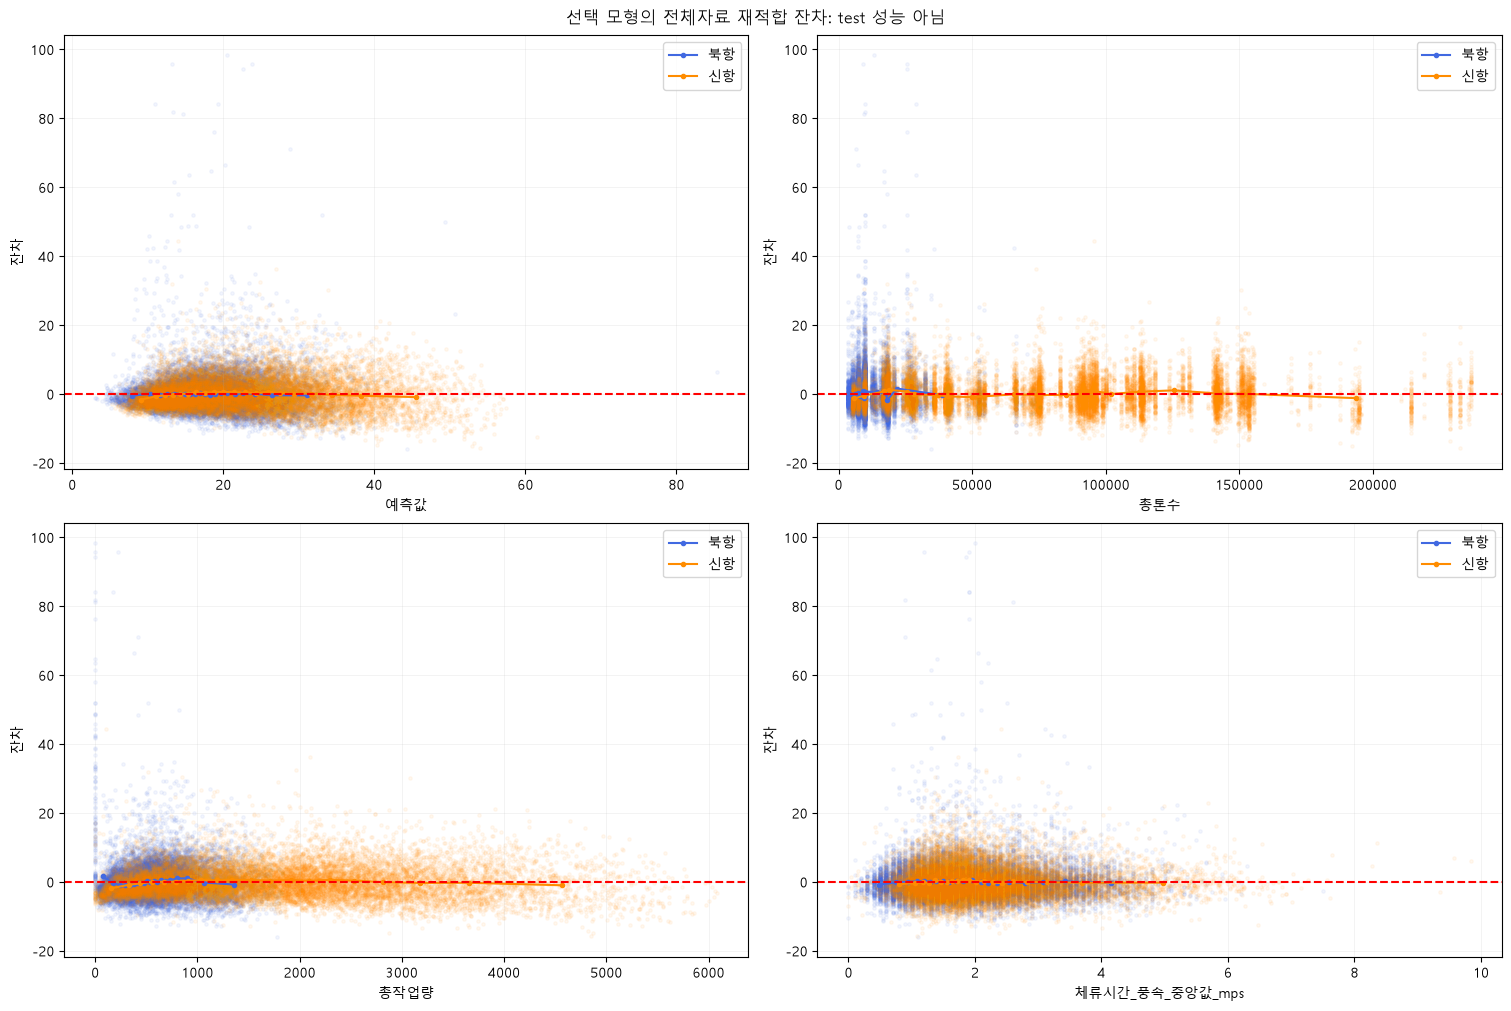

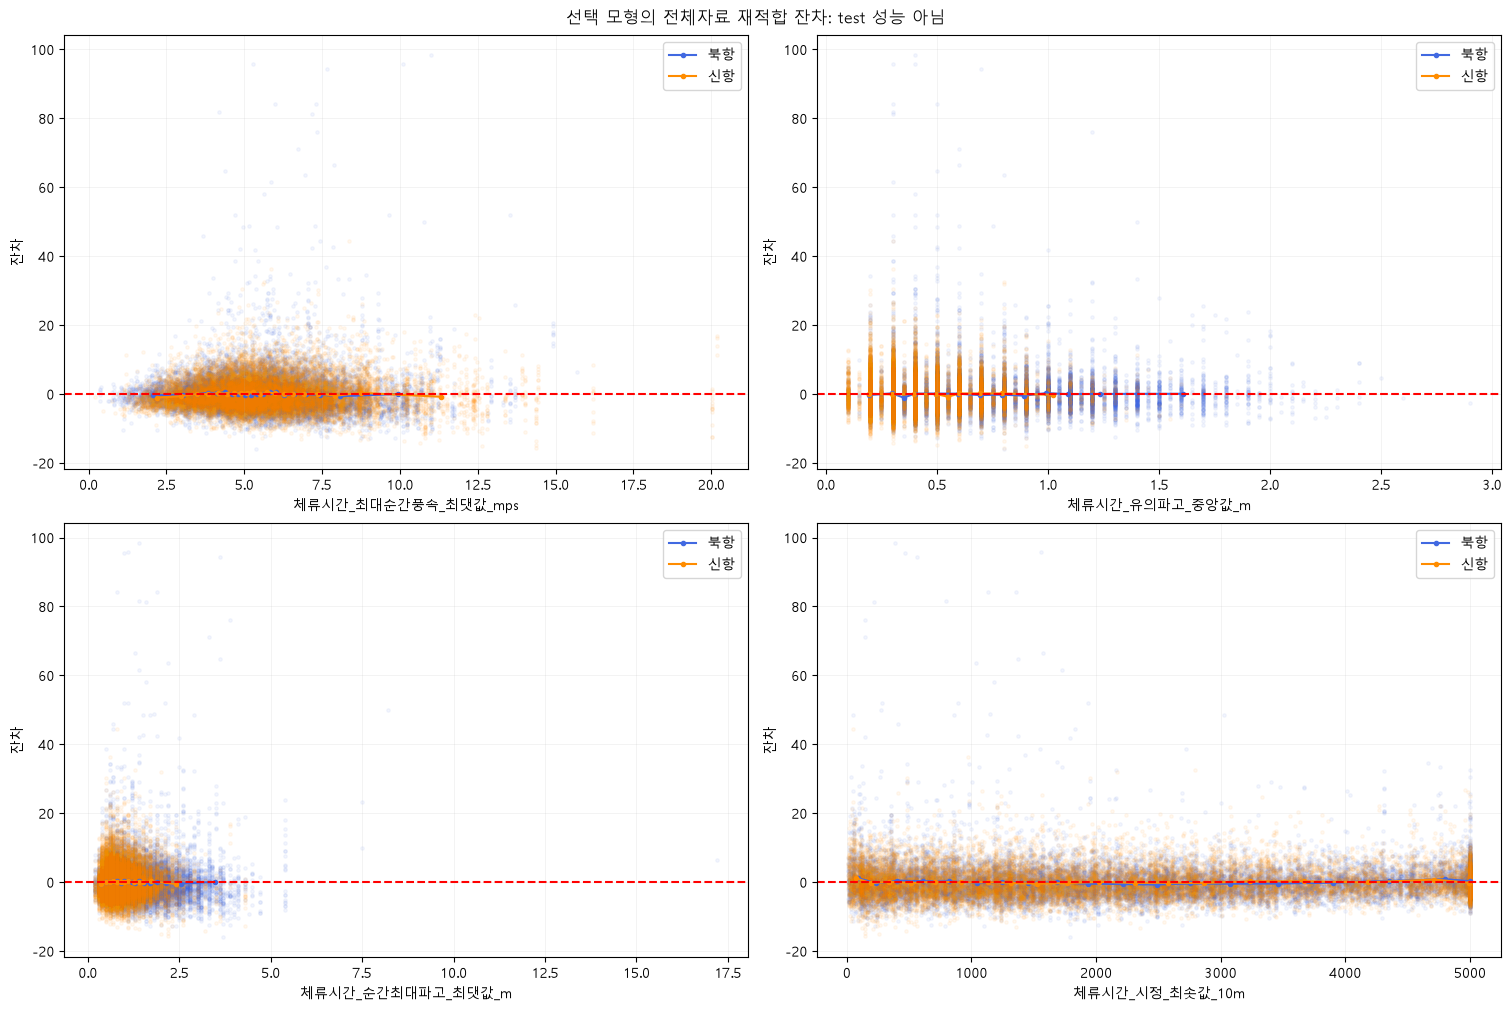

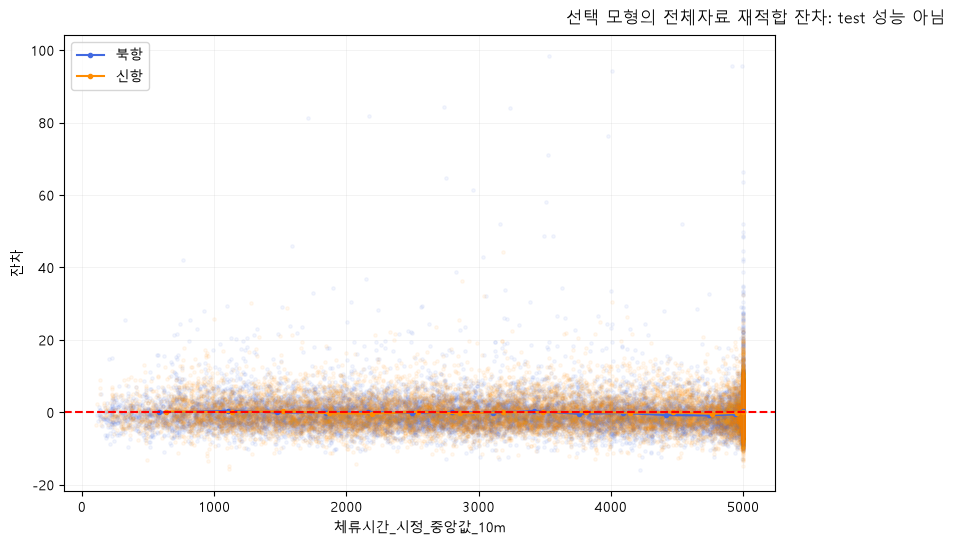

,count,mean,std
터미널,,,
BNCT,3372,2.560943,4.397053
BPTC_G,5873,-1.052403,6.217877
BPT_S,10531,0.586911,4.462870
HPNT,2817,-0.576761,4.376493
PNC,6405,-1.248579,3.660068
PNIT,3016,0.327051,4.962500


예측 체류시간 = 25.27177214
 -6.0480473 × [신항더미]
 -2.449084962 × [총톤수]
 +2.098812464 × [신항더미 × 총톤수]
 +14.56915694 × [총작업량]
 -6.890771612 × [신항더미 × 총작업량]
 +0.6706607878 × [특보유무]
 +0.06481808026 × [신항더미 × 특보유무]
 -1.383418456 × [체류시간_풍속_중앙값_mps]
 +0.3758720995 × [신항더미 × 체류시간_풍속_중앙값_mps]
 +2.348004136 × [체류시간_최대순간풍속_최댓값_mps]
 -0.8534499321 × [신항더미 × 체류시간_최대순간풍속_최댓값_mps]
 -2.088504763 × [체류시간_유의파고_중앙값_m]
 +1.245585248 × [신항더미 × 체류시간_유의파고_중앙값_m]
 +2.243432485 × [체류시간_순간최대파고_최댓값_m]
 -1.673459721 × [신항더미 × 체류시간_순간최대파고_최댓값_m]
 -1.500551035 × [체류시간_시정_최솟값_10m]
 +0.2526235933 × [신항더미 × 체류시간_시정_최솟값_10m]
 +1.047578566 × [체류시간_시정_중앙값_10m]
 -0.2291228104 × [신항더미 × 체류시간_시정_중앙값_10m]
 +0.6877012267 × [월_2]
 -0.8895454014 × [월_3]
 -0.8622564822 × [월_4]
 -0.9340863417 × [월_5]
 -0.6151807148 × [월_6]
 +0.006966835757 × [월_7]
 -0.5113012733 × [월_8]
 +0.06982735975 × [월_9]
 -0.153158913 × [월_10]
 -0.754097398 × [월_11]
 -0.5358322337 × [월_12]
 -0.1010003548 × [요일_1]
 -0.0957136155 × [요일_2]
 -0.02138552927 × [요일_3]
 

항만구분
북항    0.670661
신항    0.735479
Name: 전체자료 재적합 KPI 시간, dtype: float64

In [34]:
if FINAL_MODEL is None:
    print('9단계에서 FINAL_MODEL을 정한 뒤 이 셀을 실행하세요.')
else:
    final_data = df.loc[(df['접안일시'] >= '2021-01-01') &
                        (df['접안일시'] < '2025-01-01') &
                        (df['출항일시'] < '2025-01-01')].copy()
    final_spec = specs[FINAL_MODEL]
    final_x = make_design(final_data, final_spec)
    final_model = sm.OLS(final_data['체류시간'], final_x).fit()
    covariance = clustered_cov(final_model, final_data, 14)
    diagonal = np.diag(covariance)
    se = np.sqrt(np.where(diagonal >= 0, diagonal, np.nan))
    b = final_model.params.to_numpy()
    p = 2*norm.sf(np.abs(np.divide(b, se, out=np.full_like(b, np.nan), where=se > 0)))
    coefficients = pd.DataFrame({'회귀계수': b, '이중군집 표준오차': se,
        '95% 하한': b-1.96*se, '95% 상한': b+1.96*se, '근사 p값': p}, index=final_x.columns)
    display(coefficients)
    print('전체자료 설명용 R²:', final_model.rsquared, '/ 표본 수:', int(final_model.nobs))
    print('시간 검증 성능은 7단계의 학습모형 결과를 사용하세요.')
    print('최종 전체자료 모형 VIF')
    display(vif_table(final_x.drop(columns='const')).round(3))
    final_residual = final_data.copy()
    final_residual['예측값'] = np.asarray(final_model.fittedvalues)
    final_residual['잔차'] = np.asarray(final_model.resid)
    plot_grid(final_residual, ['예측값'] + continuous, '잔차',
              '선택 모형의 전체자료 재적합 잔차: test 성능 아님', zero=True)
    display(final_residual.groupby('터미널')['잔차'].agg(['count', 'mean', 'std']))

    equation = '예측 체류시간 = ' + f'{final_model.params["const"]:.10g}'
    for term, value in final_model.params.drop('const').items():
        equation += f'\n {value:+.10g} × [{term}]'
    print(equation)
    print('연속형 열은 (원값-학습평균)/학습표준편차를 대입합니다.')
    coefficients.to_csv(OUTPUT / '최종_전체자료_계수.csv', encoding='utf-8-sig')
    (OUTPUT / '최종_회귀식.txt').write_text(equation, encoding='utf-8-sig')
    metadata = {'모형': FINAL_MODEL, '선택 근거': SELECTION_REASON, '설정': final_spec,
                '중심': centers.to_dict(), '척도': scales.to_dict(), '기상': weather6,
                '열 순서': final_x.columns.tolist(), '전체자료 표본 수': len(final_data),
                '해석': '사후 조건부 연관; 특보 KPI는 인과효과 아님'}
    (OUTPUT / '최종_변수처리기준.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    final_model.save(str(OUTPUT / '최종_OLS모형.pickle'))

    def predict_final(frame, alert=None):
        return final_model.predict(make_design(frame, final_spec, alert=alert))

    final_contrast = kpi_contrast(test, final_spec)
    final_kpi = final_contrast.to_numpy() @ final_model.params.to_numpy()
    assert np.allclose(final_kpi, predict_final(test, 1)-predict_final(test, 0))
    final_kpi_table = test[['행ID', '항만구분']].copy()
    final_kpi_table['전체자료 재적합 KPI 시간'] = final_kpi
    display(final_kpi_table.groupby('항만구분')['전체자료 재적합 KPI 시간'].mean())
    final_kpi_table.to_csv(OUTPUT / '최종_전체자료_KPI.csv', index=False, encoding='utf-8-sig')

### 실행과 공유
처음부터 순서대로 실행한다. 6단계 그림이 많으면 `DETAIL_MODELS`를 줄인다.
팀원과 `학습_행ID.csv`, `검증_행ID.csv`, 기상 6개, 시간 통제항을 대조한다.
숫자 계수는 표준화 단위이므로 원래 단위 계수와 직접 크기를 비교하지 않는다.
결과 CSV와 최종 변수 처리 기준은 설정한 `OUTPUT` 폴더에 저장된다.

참고: [NIST 회귀모형 잔차 진단](https://itl.nist.gov/div898/handbook/pmd/section4/pmd44.htm),
[시간 순서를 지키는 검증](https://otexts.com/fpp3/tscv.html),
[statsmodels 이중 군집 공분산](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_cluster_2groups.html).